In [1]:
import os

os.environ["DRJIT_LIBOPTIX_PATH"] = (
    "/home/afanali/driver-dist/libnvoptix.so.1"
)

os.environ["LD_LIBRARY_PATH"] = (
    "/home/afanali/driver-dist:"
    + os.environ.get("LD_LIBRARY_PATH", "")
)

print("OptiX environment configured.")

OptiX environment configured.


In [2]:
import torch
import sionna

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Sionna:", sionna.__version__)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Sionna: 2.1.0


In [3]:
import mitsuba as mi

mi.set_variant("cuda_ad_mono_polarized")

print("Mitsuba variant:", mi.variant())

Mitsuba variant: cuda_ad_mono_polarized


In [4]:
from pathlib import Path

scene_path = Path(
    "/home/afanali/wcnc_project/scenes/kfupm_terrain/kfupm_terrain.xml"
)

print("Scene exists:", scene_path.exists())
print("Scene path:", scene_path)

Scene exists: True
Scene path: /home/afanali/wcnc_project/scenes/kfupm_terrain/kfupm_terrain.xml


In [5]:
import sionna.rt as rt

scene = rt.load_scene(
    str(scene_path),
    merge_shapes=False
)

scene.frequency = 3.5e9

print("KFUPM scene loaded successfully.")
print("Number of scene objects:", len(scene.objects))

KFUPM scene loaded successfully.
Number of scene objects: 2817


In [6]:
scene.tx_array = rt.PlanarArray(
    num_rows=8,
    num_cols=8,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V",
)

scene.rx_array = rt.PlanarArray(
    num_rows=2,
    num_cols=2,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V",
)

print("Transmitter array:", scene.tx_array.num_ant)
print("Receiver array:", scene.rx_array.num_ant)

Transmitter array: 64
Receiver array: 4


In [7]:
import numpy as np

gnb_positions = {
    "gNB1_B59": [-541.7, 204.4, 69.0],
    "gNB2_B21": [-513.0, -19.3, 87.0],
    "gNB3_B15": [-903.3, 98.0, 91.2],
}

for name, position in gnb_positions.items():
    scene.add(
        rt.Transmitter(
            name=name,
            position=position,
            power_dbm=30.0,
            orientation=[0.0, 0.0, 0.0],
        )
    )

print("KFUPM gNBs added:")
for name, position in gnb_positions.items():
    print(f"  {name}: {position}")

KFUPM gNBs added:
  gNB1_B59: [-541.7, 204.4, 69.0]
  gNB2_B21: [-513.0, -19.3, 87.0]
  gNB3_B15: [-903.3, 98.0, 91.2]


In [8]:
ue_position = [-600.0, 150.0, 45.0]

scene.add(
    rt.Receiver(
        name="UE_0",
        position=ue_position,
        orientation=[0.0, 0.0, 0.0],
    )
)

print("UE added at:", ue_position)

UE added at: [-600.0, 150.0, 45.0]


In [9]:
path_solver = rt.PathSolver()

paths = path_solver(
    scene=scene,
    max_depth=5,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    refraction=True,
    synthetic_array=True,
    seed=42,
)

print("Ray tracing completed.")
print("Path-delay tensor shape:", paths.tau.shape)
print("Number of paths:", paths.tau.shape[-1])

Ray tracing completed.
Path-delay tensor shape: (1, 3, 2)
Number of paths: 2


In [14]:
print("Path coefficient type:", type(paths.a))
print("Real path coefficient shape:", paths.a[0].shape)
print("Imaginary path coefficient shape:", paths.a[1].shape)
print("Path delay shape:", paths.tau.shape)
print("Source coordinates shape:", paths.sources.shape)
print("Target coordinates shape:", paths.targets.shape)

print("\nUE target coordinate:")
print(paths.targets)

print("\nMinimum path delay:")
print(paths.tau.min().numpy())

print("\nMaximum path delay:")
print(paths.tau.max().numpy())

print("\nNumber of valid propagation paths:")
print(paths.valid.sum().numpy())

Path coefficient type: <class 'tuple'>
Real path coefficient shape: (1, 4, 3, 64, 2)
Imaginary path coefficient shape: (1, 4, 3, 64, 2)
Path delay shape: (1, 3, 2)
Source coordinates shape: (3, 3)
Target coordinates shape: (3, 1)

UE target coordinate:
[[-600, 150, 45]]

Minimum path delay:


AttributeError: 'TensorXf' object has no attribute 'min'

In [15]:
import numpy as np

BW_HZ = 20e6
Q_SUBCARRIERS = 32

subcarrier_spacing = BW_HZ / Q_SUBCARRIERS

frequencies = (
    np.arange(Q_SUBCARRIERS) - (Q_SUBCARRIERS - 1) / 2
) * subcarrier_spacing

H = paths.cfr(
    frequencies=frequencies,
    normalize=False,
    normalize_delays=True,
    out_type="numpy",
)

print("Frequency-domain channel shape:", H.shape)

Frequency-domain channel shape: (1, 4, 3, 64, 1, 32)


In [17]:
print("Frequency-domain channel shape:", H.shape)

# Keep only the gNB dimension (axis 2) and average over all other dimensions
average_axes = tuple(i for i in range(H.ndim) if i != 2)

channel_power = np.mean(
    np.abs(H) ** 2,
    axis=average_axes
)

print("Average channel power per gNB:")

for i, power in enumerate(np.ravel(channel_power)):
    print(f"gNB{i+1}: {float(10*np.log10(power + 1e-30)):.2f} dB")

Frequency-domain channel shape: (1, 4, 3, 64, 1, 32)
Average channel power per gNB:
gNB1: -120.38 dB
gNB2: -118.93 dB
gNB3: -300.00 dB


In [19]:
valid_paths = paths.valid.numpy()

print("Valid-path tensor shape:", valid_paths.shape)

for gnb_idx in range(3):
    count = valid_paths[0, gnb_idx, :].sum()
    print(f"gNB{gnb_idx+1} valid paths: {int(count)}")

Valid-path tensor shape: (1, 3, 2)
gNB1 valid paths: 2
gNB2 valid paths: 2
gNB3 valid paths: 0


In [20]:
print("Path delays by gNB:")
print(paths.tau.numpy())

Path delays by gNB:
[[[ 1.0365570e-06  1.8443752e-06]
  [ 1.2287343e-06  1.3025259e-06]
  [-1.0000000e+00 -1.0000000e+00]]]


In [21]:
scene.preview()

In [22]:
scene.preview(paths=paths, clip_at=20)

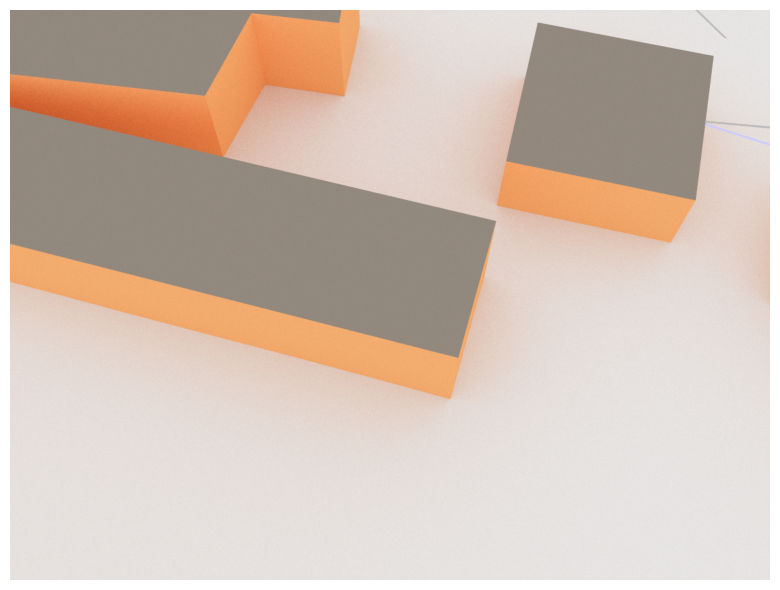

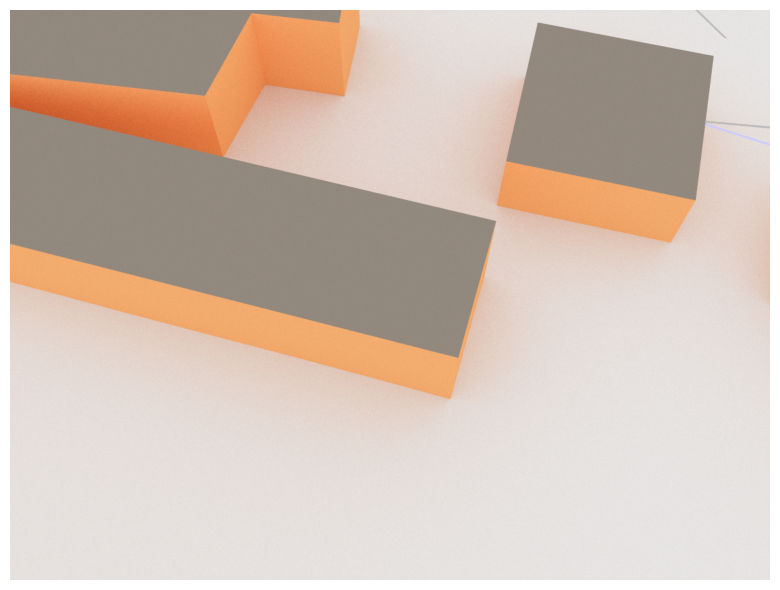

In [23]:
camera = rt.Camera(
    position=[-700.0, 20.0, 230.0],
    look_at=[-650.0, 80.0, 60.0],
)

scene.render(
    camera=camera,
    paths=paths,
    clip_at=1000,
    resolution=[1200, 900],
    num_samples=128,
)

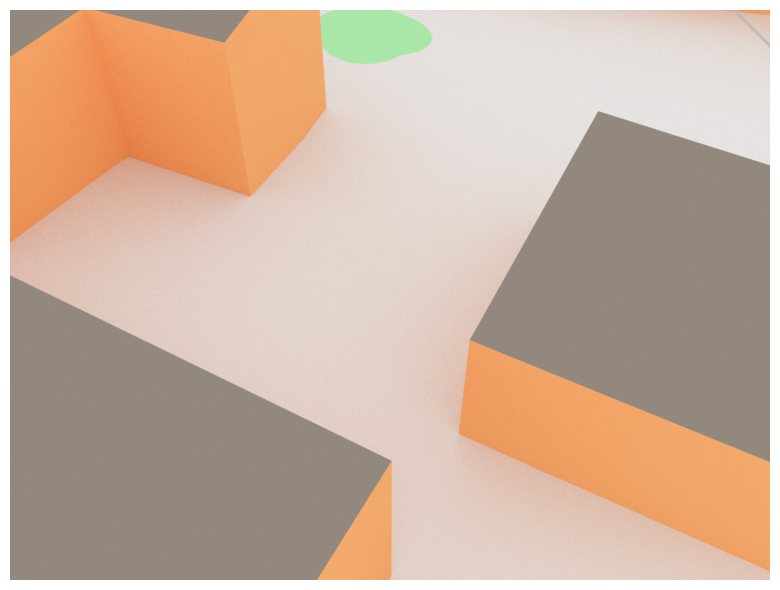

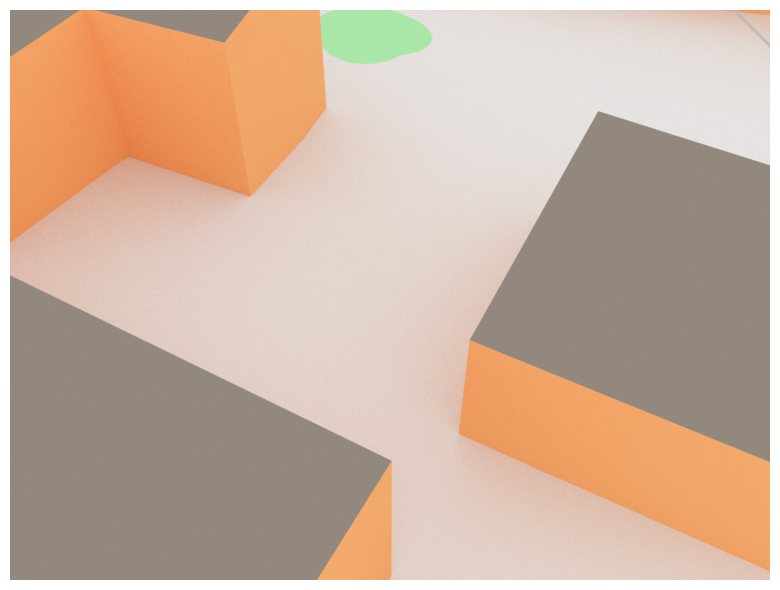

In [24]:
camera_close = rt.Camera(
    position=[-650.0, 40.0, 150.0],
    look_at=[-620.0, 100.0, 65.0],
)

scene.render(
    camera=camera_close,
    paths=paths,
    clip_at=500,
    resolution=[1200, 900],
    num_samples=128,
)

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Route waypoints based on the WCNC scenario
route_waypoints = np.array([
    [-541.7, 204.4],
    [-513.0, -19.3],
    [-746.3, 258.4],
    [-672.9, 171.3],
    [-751.1, 8.4],
    [-903.3, 98.0],
    [-598.7, 74.5],
])

# Route offset to keep the UE away from building centers
route_offset_m = 28.0

# Apply a simple lateral offset to each waypoint
route_xy = route_waypoints.copy()

for i in range(len(route_xy)):
    if i == 0:
        direction = route_xy[1] - route_xy[0]
    elif i == len(route_xy) - 1:
        direction = route_xy[-1] - route_xy[-2]
    else:
        direction = route_xy[i + 1] - route_xy[i - 1]

    direction = direction / (np.linalg.norm(direction) + 1e-9)
    normal = np.array([-direction[1], direction[0]])
    route_xy[i] += route_offset_m * normal

# Interpolate uniformly between waypoints
route_points = []

for start, end in zip(route_xy[:-1], route_xy[1:]):
    distance = np.linalg.norm(end - start)
    n_samples = max(2, int(distance / 20.0))

    segment = np.linspace(start, end, n_samples, endpoint=False)
    route_points.extend(segment)

route_points.append(route_xy[-1])
route_points = np.array(route_points)

# Initial UE height above the local scene reference
UE_Z = 45.0
ue_route = np.column_stack([
    route_points,
    np.full(len(route_points), UE_Z)
])

print("Number of UE route points:", len(ue_route))
print("First UE position:", ue_route[0])
print("Last UE position:", ue_route[-1])

Number of UE route points: 76
First UE position: [-513.92763472  207.96310632   45.        ]
Last UE position: [-594.62384    102.2017133   45.       ]


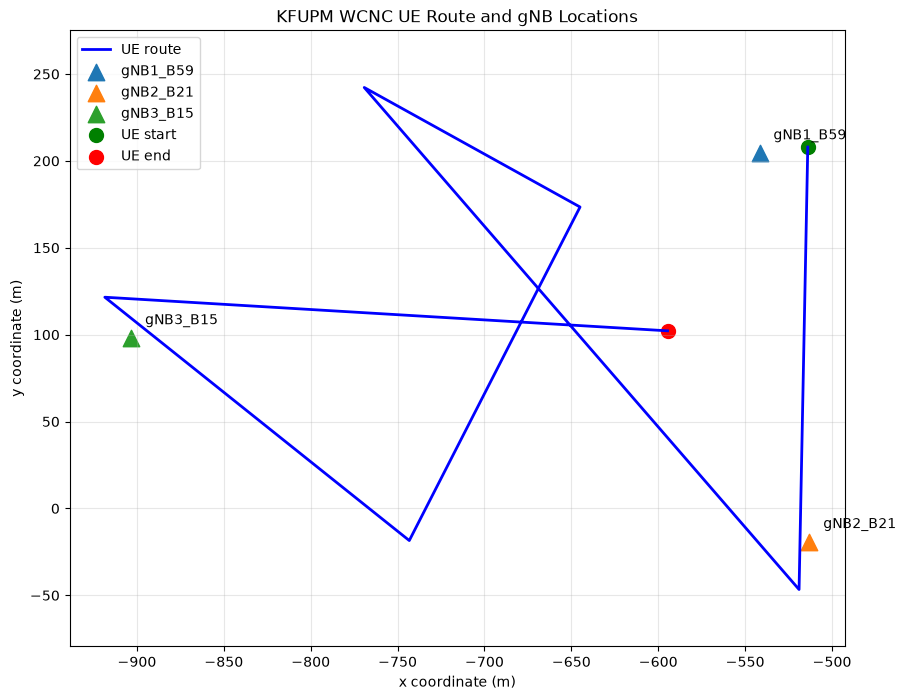

In [26]:
plt.figure(figsize=(10, 8))

plt.plot(
    ue_route[:, 0],
    ue_route[:, 1],
    "b-",
    linewidth=2,
    label="UE route",
)

for name, position in gnb_positions.items():
    plt.scatter(
        position[0],
        position[1],
        s=140,
        marker="^",
        label=name,
    )
    plt.text(
        position[0] + 8,
        position[1] + 8,
        name,
        fontsize=10,
    )

plt.scatter(
    ue_route[0, 0],
    ue_route[0, 1],
    s=100,
    color="green",
    label="UE start",
)

plt.scatter(
    ue_route[-1, 0],
    ue_route[-1, 1],
    s=100,
    color="red",
    label="UE end",
)

plt.xlabel("x coordinate (m)")
plt.ylabel("y coordinate (m)")
plt.title("KFUPM WCNC UE Route and gNB Locations")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [27]:
import plotly.graph_objects as go
import numpy as np

fig = go.Figure()

# UE route
fig.add_trace(
    go.Scatter(
        x=ue_route[:, 0],
        y=ue_route[:, 1],
        mode="lines",
        name="UE route",
        line=dict(color="royalblue", width=4),
    )
)

# Route start
fig.add_trace(
    go.Scatter(
        x=[ue_route[0, 0]],
        y=[ue_route[0, 1]],
        mode="markers",
        name="UE start",
        marker=dict(color="green", size=14, symbol="circle"),
    )
)

# Moving car/UE marker
fig.add_trace(
    go.Scatter(
        x=[ue_route[len(ue_route)//2, 0]],
        y=[ue_route[len(ue_route)//2, 1]],
        mode="markers",
        name="UE/car",
        marker=dict(
            color="black",
            size=18,
            symbol="triangle-up",
            line=dict(color="white", width=2),
        ),
    )
)

# gNBs
gnb_x = [p[0] for p in gnb_positions.values()]
gnb_y = [p[1] for p in gnb_positions.values()]
gnb_names = list(gnb_positions.keys())

fig.add_trace(
    go.Scatter(
        x=gnb_x,
        y=gnb_y,
        mode="markers+text",
        name="gNBs",
        text=gnb_names,
        textposition="top center",
        marker=dict(
            color="crimson",
            size=20,
            symbol="triangle-up",
            line=dict(color="black", width=2),
        ),
    )
)

# Route direction arrows
for i in range(0, len(ue_route) - 1, max(1, len(ue_route)//8)):
    p0 = ue_route[i]
    p1 = ue_route[i + 1]

    fig.add_annotation(
        x=p1[0],
        y=p1[1],
        ax=p0[0],
        ay=p0[1],
        xref="x",
        yref="y",
        axref="x",
        ayref="y",
        showarrow=True,
        arrowhead=3,
        arrowsize=1.2,
        arrowwidth=1.5,
        arrowcolor="royalblue",
    )

fig.update_layout(
    title="KFUPM Digital Twin: UE Route and gNB Locations",
    xaxis_title="x coordinate (m)",
    yaxis_title="y coordinate (m)",
    width=1100,
    height=800,
    template="plotly_white",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5,
    ),
)

fig.update_yaxes(scaleanchor="x", scaleratio=1)

fig.show()

In [28]:
fig.write_html(
    "/home/afanali/wcnc_project/figures/kfupm_route_interactive.html"
)

In [30]:
print("First object:", first_name)
print("SceneObject type:", type(first_object))
print("Available properties:")
print([x for x in dir(first_object) if not x.startswith("_")])

First object: Jabal_Mosque-itu_brick
SceneObject type: <class 'sionna.rt.scene_object.SceneObject'>
Available properties:
['NO_NAME_COUNTER', 'clone', 'look_at', 'mi_mesh', 'name', 'object_id', 'orientation', 'position', 'radio_material', 'scaling', 'scene', 'shape_id_to_name', 'velocity']


In [31]:
print("First mesh:", first_object.mi_mesh)
print("Mesh type:", type(first_object.mi_mesh))
print("Mesh properties:")
print([x for x in dir(first_object.mi_mesh) if not x.startswith("_")])

First mesh: PLYMesh[
  name = "Jabal_Mosque-itu_brick.ply",
  bbox = BoundingBox3f[
    min = [-812.839, 99.3898, 62.5],
    max = [-759.173, 136.434, 82.761]
  ],
  vertex_count = 8,
  vertices = [96 B of vertex data],
  face_count = 8,
  faces = [96 B of face data],
  face_normals = 1,
  bsdf = ITURadioMaterial type=brick
                   eta_r=3.910
                   sigma=0.029
                   thickness=0.100
                   scattering_coefficient=0.000
                   xpd_coefficient=0.000
]
Mesh type: <class 'mitsuba.Mesh'>
Mesh properties:
['add_attribute', 'add_texture_attribute', 'attribute_buffer', 'bbox', 'bsdf', 'build_directed_edges', 'class_name', 'compute_surface_interaction', 'differential_motion', 'edge_indices', 'effective_primitive_count', 'emitter', 'eval_attribute', 'eval_attribute_1', 'eval_attribute_3', 'eval_attribute_x', 'eval_parameterization', 'expand', 'exterior_medium', 'face_count', 'face_indices', 'face_normal', 'faces_buffer', 'has_attribute'

In [33]:
fig = go.Figure()

# Building footprints
for building in building_boxes:
    fig.add_shape(
        type="rect",
        x0=building["xmin"],
        x1=building["xmax"],
        y0=building["ymin"],
        y1=building["ymax"],
        line=dict(color="dimgray", width=0.6),
        fillcolor="lightgray",
        opacity=0.65,
    )

# UE route
fig.add_trace(
    go.Scatter(
        x=ue_route[:, 0],
        y=ue_route[:, 1],
        mode="lines",
        name="UE route",
        line=dict(color="royalblue", width=4),
    )
)

# UE/car position
car_index = len(ue_route) // 2

fig.add_trace(
    go.Scatter(
        x=[ue_route[car_index, 0]],
        y=[ue_route[car_index, 1]],
        mode="markers",
        name="UE/car",
        marker=dict(
            symbol="triangle-up",
            size=20,
            color="black",
            line=dict(color="white", width=2),
        ),
        hovertemplate=(
            "UE/car<br>"
            "x=%{x:.2f} m<br>"
            "y=%{y:.2f} m"
            "<extra></extra>"
        ),
    )
)

# gNB locations
fig.add_trace(
    go.Scatter(
        x=[p[0] for p in gnb_positions.values()],
        y=[p[1] for p in gnb_positions.values()],
        mode="markers+text",
        name="gNBs",
        text=list(gnb_positions.keys()),
        textposition="top center",
        marker=dict(
            symbol="triangle-up",
            size=22,
            color="crimson",
            line=dict(color="black", width=2),
        ),
        hovertemplate=(
            "%{text}<br>"
            "x=%{x:.2f} m<br>"
            "y=%{y:.2f} m"
            "<extra></extra>"
        ),
    )
)

# Start and end points
fig.add_trace(
    go.Scatter(
        x=[ue_route[0, 0], ue_route[-1, 0]],
        y=[ue_route[0, 1], ue_route[-1, 1]],
        mode="markers",
        name="Route endpoints",
        marker=dict(
            size=12,
            color=["green", "red"],
            symbol=["circle", "x"],
        ),
        text=["Start", "End"],
        hovertemplate="%{text}<extra></extra>",
    )
)

fig.update_layout(
    title="KFUPM Digital Twin: Building Layout, gNBs, and UE Route",
    xaxis_title="x coordinate (m)",
    yaxis_title="y coordinate (m)",
    width=1200,
    height=900,
    template="plotly_white",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5,
    ),
)

fig.update_xaxes(showgrid=True, zeroline=False)
fig.update_yaxes(scaleanchor="x", scaleratio=1, showgrid=True)

fig.show()

In [35]:
from pathlib import Path

gnb_icon_path = Path(
    "/home/afanali/wcnc_project/figures/gnb_icon.png"
)

car_icon_path = Path(
    "/home/afanali/wcnc_project/figures/car_icon.png"
)

print("gNB icon exists:", gnb_icon_path.exists())
print("Car icon exists:", car_icon_path.exists())

gNB icon exists: True
Car icon exists: True


In [36]:
import base64
from pathlib import Path
import plotly.graph_objects as go
import numpy as np

def image_data_uri(path):
    data = Path(path).read_bytes()
    encoded = base64.b64encode(data).decode("utf-8")
    return f"data:image/png;base64,{encoded}"

gnb_icon_path = Path(
    "/home/afanali/wcnc_project/figures/gnb_icon.png"
)

car_icon_path = Path(
    "/home/afanali/wcnc_project/figures/car_icon.png"
)

gnb_image = image_data_uri(gnb_icon_path)
car_image = image_data_uri(car_icon_path)

# Main activity area: B59, B21, and B15
main_gnb_names = ["gNB1_B59", "gNB2_B21", "gNB3_B15"]

main_gnb_points = np.array([
    gnb_positions[name][:2]
    for name in main_gnb_names
])

margin_x = 70
margin_y = 70

x_min = main_gnb_points[:, 0].min() - margin_x
x_max = main_gnb_points[:, 0].max() + margin_x
y_min = main_gnb_points[:, 1].min() - margin_y
y_max = main_gnb_points[:, 1].max() + margin_y

fig_focus = go.Figure()

# Actual KFUPM building footprints
for building in building_boxes:
    inside_region = (
        building["xmax"] >= x_min
        and building["xmin"] <= x_max
        and building["ymax"] >= y_min
        and building["ymin"] <= y_max
    )

    if inside_region:
        fig_focus.add_shape(
            type="rect",
            x0=building["xmin"],
            x1=building["xmax"],
            y0=building["ymin"],
            y1=building["ymax"],
            line=dict(color="#666666", width=0.5),
            fillcolor="#D9D9D9",
            opacity=0.7,
        )

# UE route
fig_focus.add_trace(
    go.Scatter(
        x=ue_route[:, 0],
        y=ue_route[:, 1],
        mode="lines",
        name="UE route",
        line=dict(color="#1769AA", width=3),
    )
)

# Route endpoints
fig_focus.add_trace(
    go.Scatter(
        x=[ue_route[0, 0], ue_route[-1, 0]],
        y=[ue_route[0, 1], ue_route[-1, 1]],
        mode="markers+text",
        text=["Start", "End"],
        textposition="top center",
        name="Route endpoints",
        marker=dict(
            color=["green", "red"],
            size=10,
            symbol=["circle", "x"],
        ),
    )
)

# Add gNB image icons
for name in main_gnb_names:
    x, y = gnb_positions[name][:2]

    fig_focus.add_layout_image(
        dict(
            source=gnb_image,
            x=x,
            y=y,
            xref="x",
            yref="y",
            xanchor="center",
            yanchor="middle",
            sizex=28,
            sizey=28,
            sizing="contain",
            opacity=1.0,
            layer="above",
        )
    )

    fig_focus.add_annotation(
        x=x,
        y=y + 20,
        text=name,
        showarrow=False,
        font=dict(size=13, color="#8B0000"),
        bgcolor="rgba(255,255,255,0.8)",
    )

# Add car icon at the middle of the UE route
car_index = len(ue_route) // 2
car_x, car_y = ue_route[car_index, :2]

fig_focus.add_layout_image(
    dict(
        source=car_image,
        x=car_x,
        y=car_y,
        xref="x",
        yref="y",
        xanchor="center",
        yanchor="middle",
        sizex=24,
        sizey=24,
        sizing="contain",
        opacity=1.0,
        layer="above",
    )
)

fig_focus.add_annotation(
    x=car_x,
    y=car_y - 20,
    text="UE vehicle",
    showarrow=False,
    font=dict(size=12, color="black"),
    bgcolor="rgba(255,255,255,0.8)",
)

fig_focus.update_layout(
    title="KFUPM Main Activity Region: B59–B21–B15",
    width=1200,
    height=850,
    template="plotly_white",
    xaxis_title="x coordinate (m)",
    yaxis_title="y coordinate (m)",
    xaxis=dict(range=[x_min, x_max]),
    yaxis=dict(
        range=[y_min, y_max],
        scaleanchor="x",
        scaleratio=1,
    ),
)

fig_focus.show()

fig_focus.write_html(
    "/home/afanali/wcnc_project/figures/kfupm_main_activity_region.html"
)

print("Interactive figure saved successfully.")

Interactive figure saved successfully.


In [38]:
# Stylized road corridor following the UE trajectory
ax.plot(
    ue_route[:, 0],
    ue_route[:, 1],
    color="#A7A7A7",
    linewidth=20,
    solid_capstyle="round",
    zorder=2,
    label="Road corridor",
)

# Road centerline
ax.plot(
    ue_route[:, 0],
    ue_route[:, 1],
    color="#F7F7F7",
    linewidth=1.8,
    linestyle="--",
    zorder=3,
)

In [39]:
building_labels = {
    "Building_59_Electrical_Engineering_Dept":
        "Electrical Engineering Department (B59)",

    "Building_21_Administration":
        "Administration Building (B21)",

    "Building_15_Research_Institute":
        "Research Institute (B15)",

    "Building_5_Mathematics_department":
        "Mathematics Department (B5)",

    "Building_6_Physics_department":
        "Physics Department (B6)",

    "Building_14_ITC":
        "Information Technology Center (B14)",

    "Building_8_Main_Liberary":
        "Main Library (B8)",
}

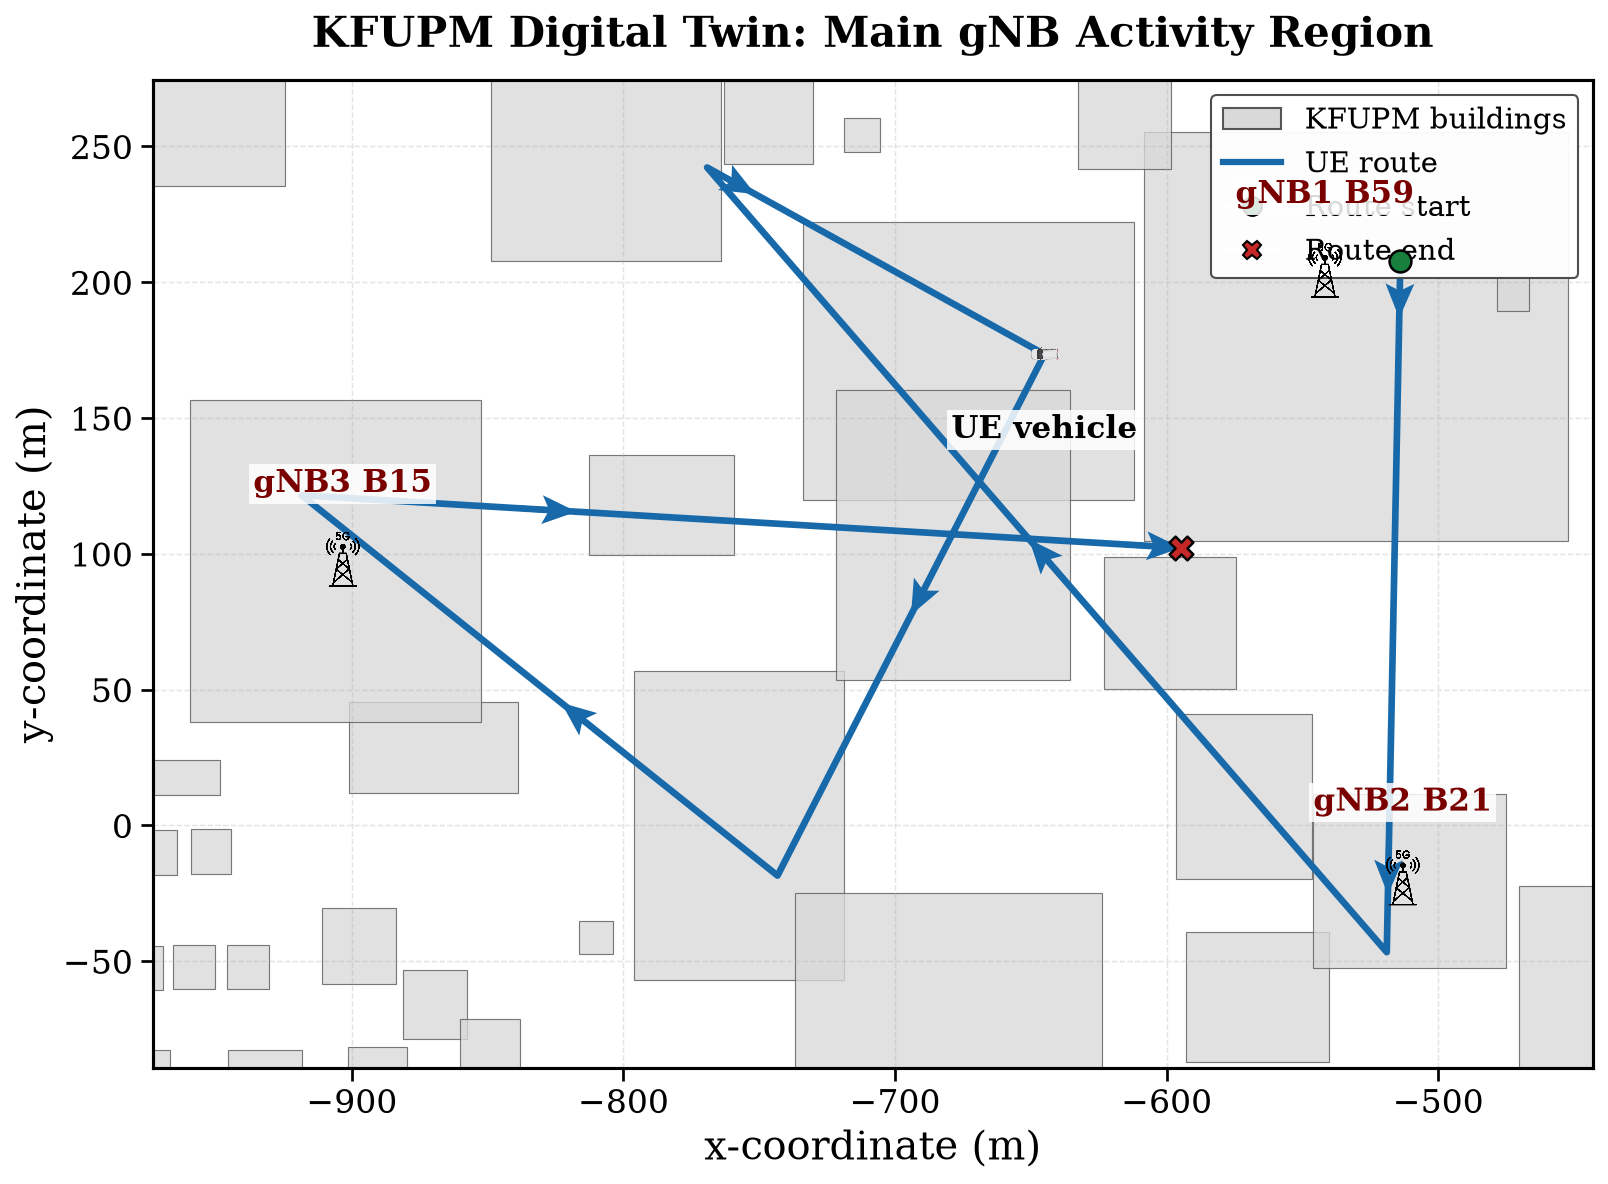

Saved:
/home/afanali/wcnc_project/figures/KFUPM_main_activity_region_IEEE.pdf
/home/afanali/wcnc_project/figures/KFUPM_main_activity_region_IEEE.png


In [41]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path
import numpy as np

# IEEE-style font settings
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 19,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 14,
    "axes.linewidth": 1.5,
    "figure.dpi": 150,
    "savefig.dpi": 600,
})

# Focus region around B59, B21, and B15
main_gnb_names = ["gNB1_B59", "gNB2_B21", "gNB3_B15"]

main_gnb_points = np.array([
    gnb_positions[name][:2]
    for name in main_gnb_names
])

margin_x = 70
margin_y = 70

x_min = main_gnb_points[:, 0].min() - margin_x
x_max = main_gnb_points[:, 0].max() + margin_x
y_min = main_gnb_points[:, 1].min() - margin_y
y_max = main_gnb_points[:, 1].max() + margin_y

fig, ax = plt.subplots(figsize=(11, 8.5))

# Plot actual building footprints
for building in building_boxes:
    inside_region = (
        building["xmax"] >= x_min
        and building["xmin"] <= x_max
        and building["ymax"] >= y_min
        and building["ymin"] <= y_max
    )

    if inside_region:
        width = building["xmax"] - building["xmin"]
        height = building["ymax"] - building["ymin"]

        rectangle = plt.Rectangle(
            (building["xmin"], building["ymin"]),
            width,
            height,
            facecolor="#D9D9D9",
            edgecolor="#555555",
            linewidth=0.55,
            alpha=0.78,
            zorder=1,
        )

        ax.add_patch(rectangle)

# Plot UE route
ax.plot(
    ue_route[:, 0],
    ue_route[:, 1],
    color="#1769AA",
    linewidth=3.2,
    zorder=4,
    label="UE route",
)

# Add route direction arrows
arrow_indices = np.linspace(
    0,
    len(ue_route) - 2,
    8,
    dtype=int,
)

for i in arrow_indices:
    dx = ue_route[i + 1, 0] - ue_route[i, 0]
    dy = ue_route[i + 1, 1] - ue_route[i, 1]

    ax.quiver(
        ue_route[i, 0],
        ue_route[i, 1],
        dx,
        dy,
        angles="xy",
        scale_units="xy",
        scale=1,
        color="#1769AA",
        width=0.004,
        headwidth=5,
        headlength=6,
        headaxislength=5,
        zorder=5,
    )

# Start and end points
ax.scatter(
    ue_route[0, 0],
    ue_route[0, 1],
    s=110,
    color="#16803C",
    edgecolor="black",
    linewidth=1.2,
    zorder=7,
)

ax.scatter(
    ue_route[-1, 0],
    ue_route[-1, 1],
    s=130,
    color="#C62828",
    marker="X",
    edgecolor="black",
    linewidth=1.2,
    zorder=7,
)

# Load icons
gnb_icon = mpimg.imread(
    "/home/afanali/wcnc_project/figures/gnb_icon.png"
)

car_icon = mpimg.imread(
    "/home/afanali/wcnc_project/figures/car_icon.png"
)

# Add gNB icons
for name in main_gnb_names:
    x, y = gnb_positions[name][:2]

    icon = OffsetImage(gnb_icon, zoom=0.055)
    annotation = AnnotationBbox(
        icon,
        (x, y),
        frameon=False,
        box_alignment=(0.5, 0.5),
        zorder=8,
    )

    ax.add_artist(annotation)

    ax.text(
        x,
        y + 22,
        name.replace("_", " "),
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
        color="#7A0000",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=2,
        ),
        zorder=9,
    )

# Add car icon
car_index = len(ue_route) // 2
car_x, car_y = ue_route[car_index, :2]

car_artist = OffsetImage(car_icon, zoom=0.045)
car_annotation = AnnotationBbox(
    car_artist,
    (car_x, car_y),
    frameon=False,
    box_alignment=(0.5, 0.5),
    zorder=10,
)

ax.add_artist(car_annotation)

ax.text(
    car_x,
    car_y - 22,
    "UE vehicle",
    ha="center",
    va="top",
    fontsize=15,
    fontweight="bold",
    color="black",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.85,
        pad=2,
    ),
    zorder=11,
)

# Axis and layout formatting
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("x-coordinate (m)")
ax.set_ylabel("y-coordinate (m)")

ax.set_title(
    "KFUPM Digital Twin: Main gNB Activity Region",
    pad=16,
    fontweight="bold",
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35,
    zorder=0,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    length=6,
    width=1.3,
)

# Professional legend
legend_items = [
    Patch(
        facecolor="#D9D9D9",
        edgecolor="#555555",
        label="KFUPM buildings",
    ),
    Line2D(
        [0],
        [0],
        color="#1769AA",
        linewidth=3,
        label="UE route",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#16803C",
        markeredgecolor="black",
        markersize=9,
        label="Route start",
    ),
    Line2D(
        [0],
        [0],
        marker="X",
        color="w",
        markerfacecolor="#C62828",
        markeredgecolor="black",
        markersize=9,
        label="Route end",
    ),
]

ax.legend(
    handles=legend_items,
    loc="upper right",
    frameon=True,
    framealpha=0.95,
    edgecolor="#444444",
)

building_labels = {
    "Building_59_Electrical_Engineering_Dept":
        "Electrical Engineering Department (B59)",

    "Building_21_Administration":
        "Administration Building (B21)",

    "Building_15_Research_Institute":
        "Research Institute (B15)",

    "Building_5_Mathematics_department":
        "Mathematics Department (B5)",

    "Building_6_Physics_department":
        "Physics Department (B6)",

    "Building_14_ITC":
        "Information Technology Center (B14)",

    "Building_8_Main_Liberary":
        "Main Library (B8)",
}
plt.tight_layout()

# Save publication-quality outputs
figure_dir = Path("/home/afanali/wcnc_project/figures")

fig.savefig(
    figure_dir / "KFUPM_main_activity_region_IEEE.pdf",
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "KFUPM_main_activity_region_IEEE.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(figure_dir / "KFUPM_main_activity_region_IEEE.pdf")
print(figure_dir / "KFUPM_main_activity_region_IEEE.png")

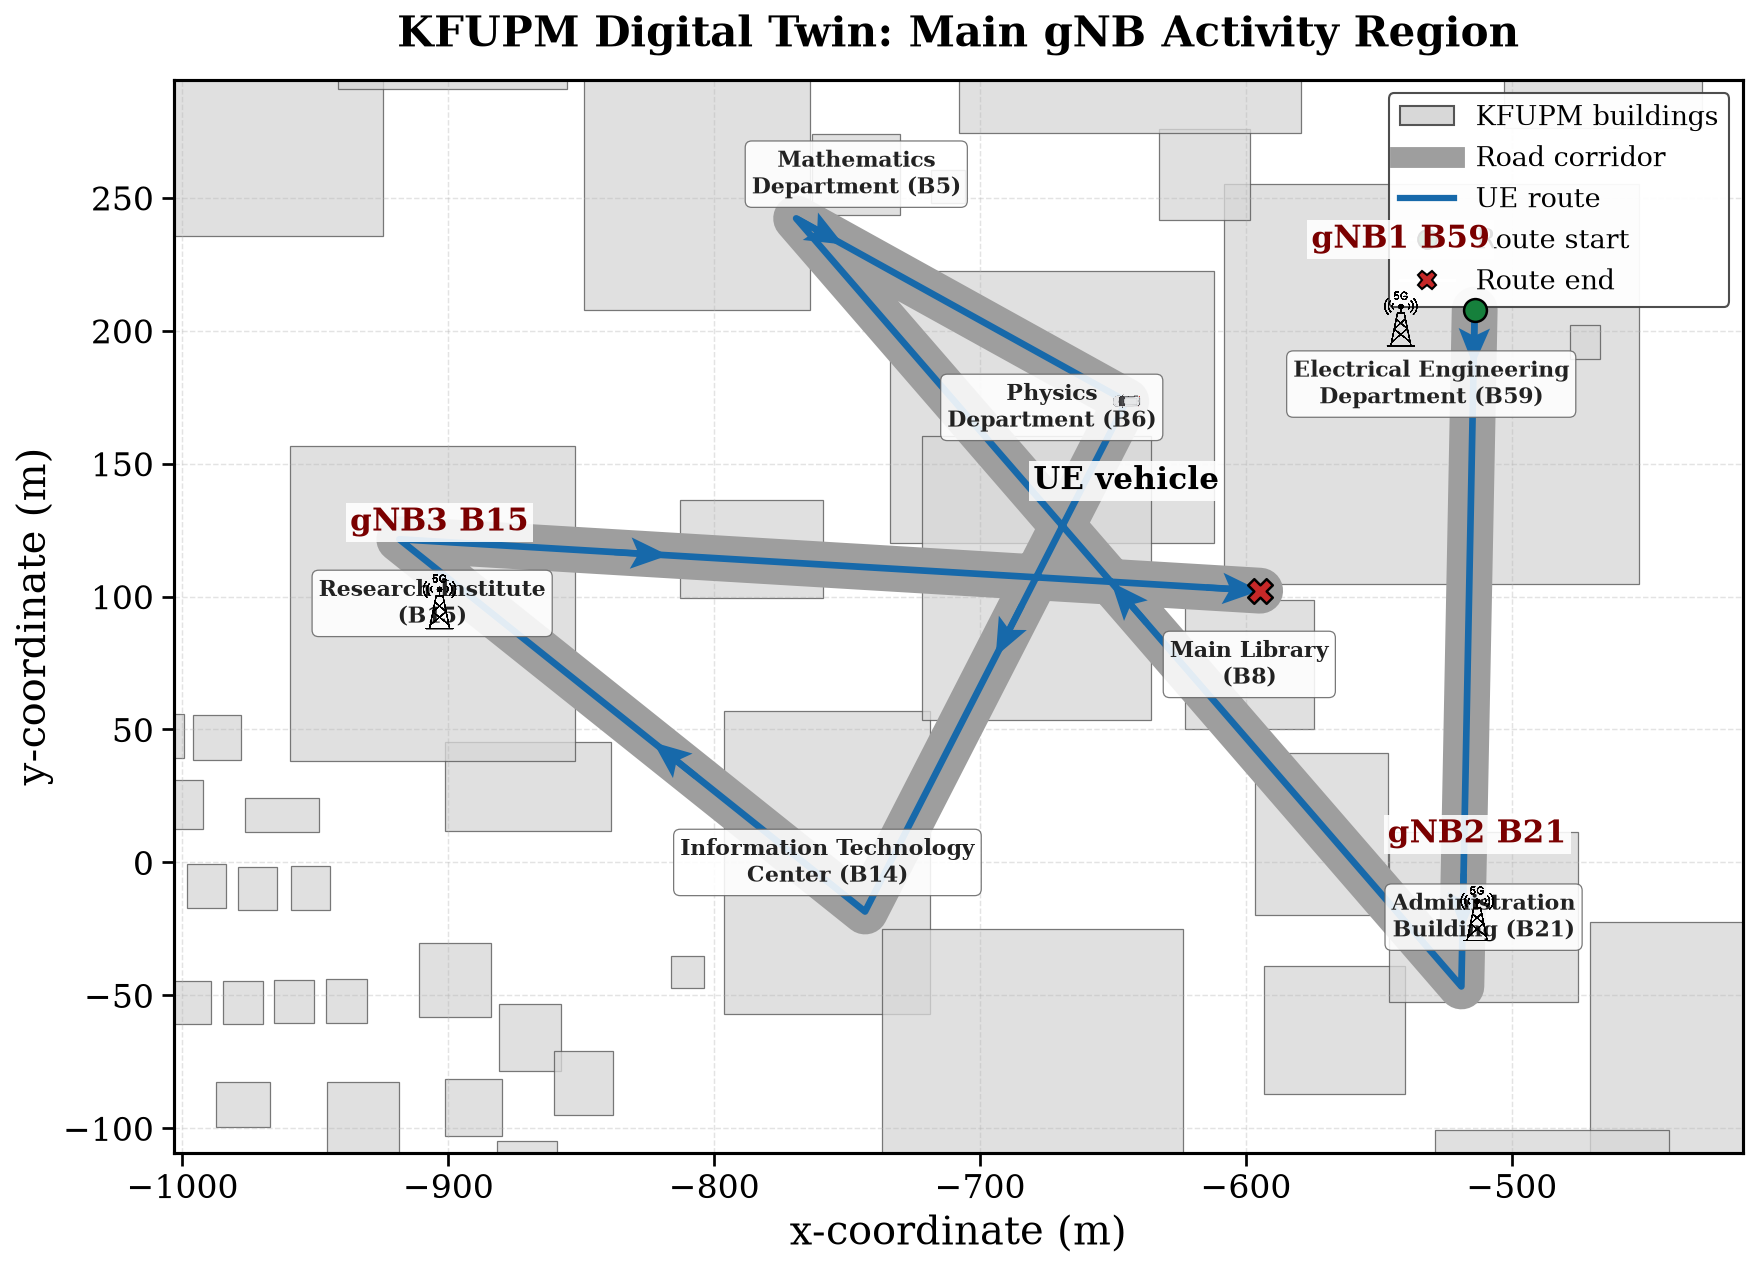

Saved PDF: /home/afanali/wcnc_project/figures/KFUPM_main_activity_region_IEEE.pdf
Saved PNG: /home/afanali/wcnc_project/figures/KFUPM_main_activity_region_IEEE.png


In [42]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path
import numpy as np

# IEEE-style formatting
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 19,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 13,
    "axes.linewidth": 1.5,
    "figure.dpi": 150,
    "savefig.dpi": 600,
})

# Main gNB region
main_gnb_names = ["gNB1_B59", "gNB2_B21", "gNB3_B15"]

main_gnb_points = np.array([
    gnb_positions[name][:2]
    for name in main_gnb_names
])

margin_x = 100
margin_y = 90

x_min = main_gnb_points[:, 0].min() - margin_x
x_max = main_gnb_points[:, 0].max() + margin_x
y_min = main_gnb_points[:, 1].min() - margin_y
y_max = main_gnb_points[:, 1].max() + margin_y

fig, ax = plt.subplots(figsize=(12, 9))

# Full building names
building_labels = {
    "Building_59_Electrical_Engineering_Dept":
        "Electrical Engineering\nDepartment (B59)",

    "Building_21_Administration":
        "Administration\nBuilding (B21)",

    "Building_15_Research_Institute":
        "Research Institute\n(B15)",

    "Building_5_Mathematics_department":
        "Mathematics\nDepartment (B5)",

    "Building_6_Physics_department":
        "Physics\nDepartment (B6)",

    "Building_14_ITC":
        "Information Technology\nCenter (B14)",

    "Building_8_Main_Liberary":
        "Main Library\n(B8)",
}

# Plot building footprints
for building in building_boxes:

    inside_region = (
        building["xmax"] >= x_min
        and building["xmin"] <= x_max
        and building["ymax"] >= y_min
        and building["ymin"] <= y_max
    )

    if not inside_region:
        continue

    width = building["xmax"] - building["xmin"]
    height = building["ymax"] - building["ymin"]

    ax.add_patch(
        plt.Rectangle(
            (building["xmin"], building["ymin"]),
            width,
            height,
            facecolor="#D8D8D8",
            edgecolor="#555555",
            linewidth=0.6,
            alpha=0.78,
            zorder=1,
        )
    )

# Road corridor
ax.plot(
    ue_route[:, 0],
    ue_route[:, 1],
    color="#9E9E9E",
    linewidth=22,
    solid_capstyle="round",
    zorder=2,
)

# Road centerline
ax.plot(
    ue_route[:, 0],
    ue_route[:, 1],
    color="white",
    linewidth=2.0,
    linestyle="--",
    zorder=3,
)

# UE route
ax.plot(
    ue_route[:, 0],
    ue_route[:, 1],
    color="#1769AA",
    linewidth=3.2,
    zorder=4,
)

# Route direction arrows
arrow_indices = np.linspace(
    0,
    len(ue_route) - 2,
    8,
    dtype=int,
)

for i in arrow_indices:
    dx = ue_route[i + 1, 0] - ue_route[i, 0]
    dy = ue_route[i + 1, 1] - ue_route[i, 1]

    ax.quiver(
        ue_route[i, 0],
        ue_route[i, 1],
        dx,
        dy,
        angles="xy",
        scale_units="xy",
        scale=1,
        color="#1769AA",
        width=0.004,
        headwidth=5,
        headlength=6,
        headaxislength=5,
        zorder=5,
    )

# Route start and end
ax.scatter(
    ue_route[0, 0],
    ue_route[0, 1],
    s=120,
    color="#16803C",
    edgecolor="black",
    linewidth=1.2,
    zorder=8,
)

ax.scatter(
    ue_route[-1, 0],
    ue_route[-1, 1],
    s=140,
    color="#C62828",
    marker="X",
    edgecolor="black",
    linewidth=1.2,
    zorder=8,
)

# Load downloaded icons
gnb_icon = mpimg.imread(
    "/home/afanali/wcnc_project/figures/gnb_icon.png"
)

car_icon = mpimg.imread(
    "/home/afanali/wcnc_project/figures/car_icon.png"
)

# Add gNB icons and labels
for name in main_gnb_names:

    x, y = gnb_positions[name][:2]

    gnb_artist = OffsetImage(
        gnb_icon,
        zoom=0.055,
    )

    ax.add_artist(
        AnnotationBbox(
            gnb_artist,
            (x, y),
            frameon=False,
            box_alignment=(0.5, 0.5),
            zorder=10,
        )
    )

    ax.text(
        x,
        y + 24,
        name.replace("_", " "),
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
        color="#7A0000",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.88,
            pad=2,
        ),
        zorder=11,
    )

# Add UE vehicle icon
car_index = len(ue_route) // 2
car_x, car_y = ue_route[car_index, :2]

car_artist = OffsetImage(
    car_icon,
    zoom=0.045,
)

ax.add_artist(
    AnnotationBbox(
        car_artist,
        (car_x, car_y),
        frameon=False,
        box_alignment=(0.5, 0.5),
        zorder=12,
    )
)

ax.text(
    car_x,
    car_y - 24,
    "UE vehicle",
    ha="center",
    va="top",
    fontsize=15,
    fontweight="bold",
    color="black",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.88,
        pad=2,
    ),
    zorder=13,
)

# Add full building labels
for building in building_boxes:

    raw_name = building["name"]

    if raw_name not in building_labels:
        continue

    inside_region = (
        building["xmax"] >= x_min
        and building["xmin"] <= x_max
        and building["ymax"] >= y_min
        and building["ymin"] <= y_max
    )

    if not inside_region:
        continue

    label_x = (
        building["xmin"] + building["xmax"]
    ) / 2

    label_y = (
        building["ymin"] + building["ymax"]
    ) / 2

    ax.text(
        label_x,
        label_y,
        building_labels[raw_name],
        ha="center",
        va="center",
        fontsize=10.5,
        fontweight="bold",
        color="#222222",
        bbox=dict(
            facecolor="white",
            edgecolor="#666666",
            linewidth=0.6,
            alpha=0.88,
            boxstyle="round,pad=0.3",
        ),
        zorder=9,
    )

# Axes and layout
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("x-coordinate (m)")
ax.set_ylabel("y-coordinate (m)")

ax.set_title(
    "KFUPM Digital Twin: Main gNB Activity Region",
    pad=16,
    fontweight="bold",
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35,
    zorder=0,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    length=6,
    width=1.3,
)

# IEEE-style legend
legend_items = [
    Patch(
        facecolor="#D8D8D8",
        edgecolor="#555555",
        label="KFUPM buildings",
    ),
    Line2D(
        [0],
        [0],
        color="#9E9E9E",
        linewidth=10,
        label="Road corridor",
    ),
    Line2D(
        [0],
        [0],
        color="#1769AA",
        linewidth=3,
        label="UE route",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#16803C",
        markeredgecolor="black",
        markersize=9,
        label="Route start",
    ),
    Line2D(
        [0],
        [0],
        marker="X",
        color="w",
        markerfacecolor="#C62828",
        markeredgecolor="black",
        markersize=9,
        label="Route end",
    ),
]

ax.legend(
    handles=legend_items,
    loc="upper right",
    frameon=True,
    framealpha=0.95,
    edgecolor="#444444",
)

plt.tight_layout()

# Save IEEE-quality outputs
figure_dir = Path(
    "/home/afanali/wcnc_project/figures"
)

pdf_path = figure_dir / "KFUPM_main_activity_region_IEEE.pdf"
png_path = figure_dir / "KFUPM_main_activity_region_IEEE.png"

fig.savefig(
    pdf_path,
    bbox_inches="tight",
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)

In [43]:
# Select a manageable number of ray-tracing samples initially
num_route_samples = 20

sample_indices = np.linspace(
    0,
    len(ue_route) - 1,
    num_route_samples,
    dtype=int,
)

sampled_positions = ue_route[sample_indices]

# Reuse the existing UE receiver
ue_device = scene.get("UE_0")

path_solver = rt.PathSolver(
    deterministic=True
)

digital_twin_records = []

for step, position in enumerate(sampled_positions):

    # Move the UE in the digital twin
    ue_device.position = position.tolist()

    # Compute propagation paths
    route_paths = path_solver(
        scene=scene,
        max_depth=5,
        los=True,
        specular_reflection=True,
        diffuse_reflection=False,
        refraction=True,
        synthetic_array=True,
        seed=100 + step,
    )

    # Compute the frequency-domain channel
    route_H = route_paths.cfr(
        frequencies=frequencies,
        normalize=False,
        normalize_delays=True,
        out_type="numpy",
    )

    # Average over all dimensions except the gNB dimension
    channel_power = np.mean(
        np.abs(route_H) ** 2,
        axis=tuple(
            i for i in range(route_H.ndim)
            if i != 2
        ),
    )

    valid_tensor = route_paths.valid.numpy()
    valid_counts = np.array([
        valid_tensor[0, gnb_idx, :].sum()
        for gnb_idx in range(3)
    ])

    channel_power_db = 10 * np.log10(
        np.asarray(channel_power) + 1e-30
    )

    best_gnb = int(np.argmax(channel_power_db))

    digital_twin_records.append({
        "step": step,
        "route_index": int(sample_indices[step]),
        "position": np.asarray(position),
        "channel_power_db": channel_power_db,
        "valid_path_counts": valid_counts,
        "best_gnb": best_gnb,
        "paths": route_paths,
        "channel": route_H,
    })

    print(
        f"Step {step+1:02d}/{num_route_samples}: "
        f"position={np.round(position, 1)}, "
        f"power={np.round(channel_power_db, 2)}, "
        f"best=gNB{best_gnb+1}"
    )

print(
    f"\nDigital Twin sequence created: "
    f"{len(digital_twin_records)} observations"
)

Step 01/20: position=[-513.9  208.    45. ], power=[-110.34 -104.34 -300.  ], best=gNB2
Step 02/20: position=[-515.2  144.3   45. ], power=[-112.16 -113.21 -300.  ], best=gNB1
Step 03/20: position=[-516.9   59.4   45. ], power=[-300.   -111.88 -300.  ], best=gNB2
Step 04/20: position=[-518.5  -25.4   45. ], power=[-135.72 -113.15 -121.06], best=gNB2
Step 05/20: position=[-558.4   -1.    45. ], power=[-124.96 -110.16 -300.  ], best=gNB2
Step 06/20: position=[-611.1   59.8   45. ], power=[-135.73 -112.71 -300.  ], best=gNB2
Step 07/20: position=[-663.8  120.6   45. ], power=[-300.   -124.99 -300.  ], best=gNB2
Step 08/20: position=[-716.5  181.4   45. ], power=[-116.16 -116.2  -300.  ], best=gNB1
Step 09/20: position=[-769.2  242.2   45. ], power=[-112.49 -117.07 -300.  ], best=gNB1
Step 10/20: position=[-698.2  202.9   45. ], power=[-300.   -109.16 -300.  ], best=gNB2
Step 11/20: position=[-654.8  154.3   45. ], power=[-300.   -300.   -131.93], best=gNB3
Step 12/20: position=[-694.1   7

In [44]:
# Compute route velocity, acceleration, and heading
route_positions = np.asarray(ue_route)

route_velocity = np.gradient(
    route_positions,
    0.1,
    axis=0,
)

route_acceleration = np.gradient(
    route_velocity,
    0.1,
    axis=0,
)

route_heading = np.arctan2(
    route_velocity[:, 1],
    route_velocity[:, 0],
)

for record in digital_twin_records:

    route_index = record["route_index"]

    record["velocity"] = route_velocity[route_index]
    record["acceleration"] = route_acceleration[route_index]
    record["heading"] = route_heading[route_index]

print("Mobility features added.")
print(digital_twin_records[0]["velocity"])
print(digital_twin_records[0]["acceleration"])
print(digital_twin_records[0]["heading"])

Mobility features added.
[  -4.17627536 -212.18830846    0.        ]
[0. 0. 0.]
-1.5904757155917293


In [45]:
def ray_rectangle_distance(
    origin,
    direction,
    xmin,
    xmax,
    ymin,
    ymax,
):
    """
    Return the distance from a 2D ray to an axis-aligned building rectangle.
    Returns np.inf if there is no forward intersection.
    """

    ox, oy = origin
    dx, dy = direction

    distances = []

    if abs(dx) > 1e-12:
        for x in [xmin, xmax]:
            t = (x - ox) / dx
            y = oy + t * dy

            if t >= 0 and ymin <= y <= ymax:
                distances.append(t)

    if abs(dy) > 1e-12:
        for y in [ymin, ymax]:
            t = (y - oy) / dy
            x = ox + t * dx

            if t >= 0 and xmin <= x <= xmax:
                distances.append(t)

    if not distances:
        return np.inf

    return min(distances)


def generate_lidar_scan(
    position,
    building_boxes,
    num_beams=72,
    max_range=250.0,
):
    """
    Generate a synthetic 2D LiDAR scan from the KFUPM building geometry.
    """

    origin = np.asarray(position[:2], dtype=float)

    angles = np.linspace(
        -np.pi,
        np.pi,
        num_beams,
        endpoint=False,
    )

    ranges = np.full(num_beams, max_range)

    for beam_index, angle in enumerate(angles):

        direction = np.array([
            np.cos(angle),
            np.sin(angle),
        ])

        for building in building_boxes:

            distance = ray_rectangle_distance(
                origin,
                direction,
                building["xmin"],
                building["xmax"],
                building["ymin"],
                building["ymax"],
            )

            if distance < ranges[beam_index]:
                ranges[beam_index] = min(
                    distance,
                    max_range,
                )

    return angles, ranges


for record in digital_twin_records:

    angles, ranges = generate_lidar_scan(
        record["position"],
        building_boxes,
        num_beams=72,
        max_range=250.0,
    )

    record["lidar_angles"] = angles
    record["lidar_ranges"] = ranges

print("LiDAR-like observations added.")
print(
    "LiDAR vector shape:",
    digital_twin_records[0]["lidar_ranges"].shape,
)

LiDAR-like observations added.
LiDAR vector shape: (72,)


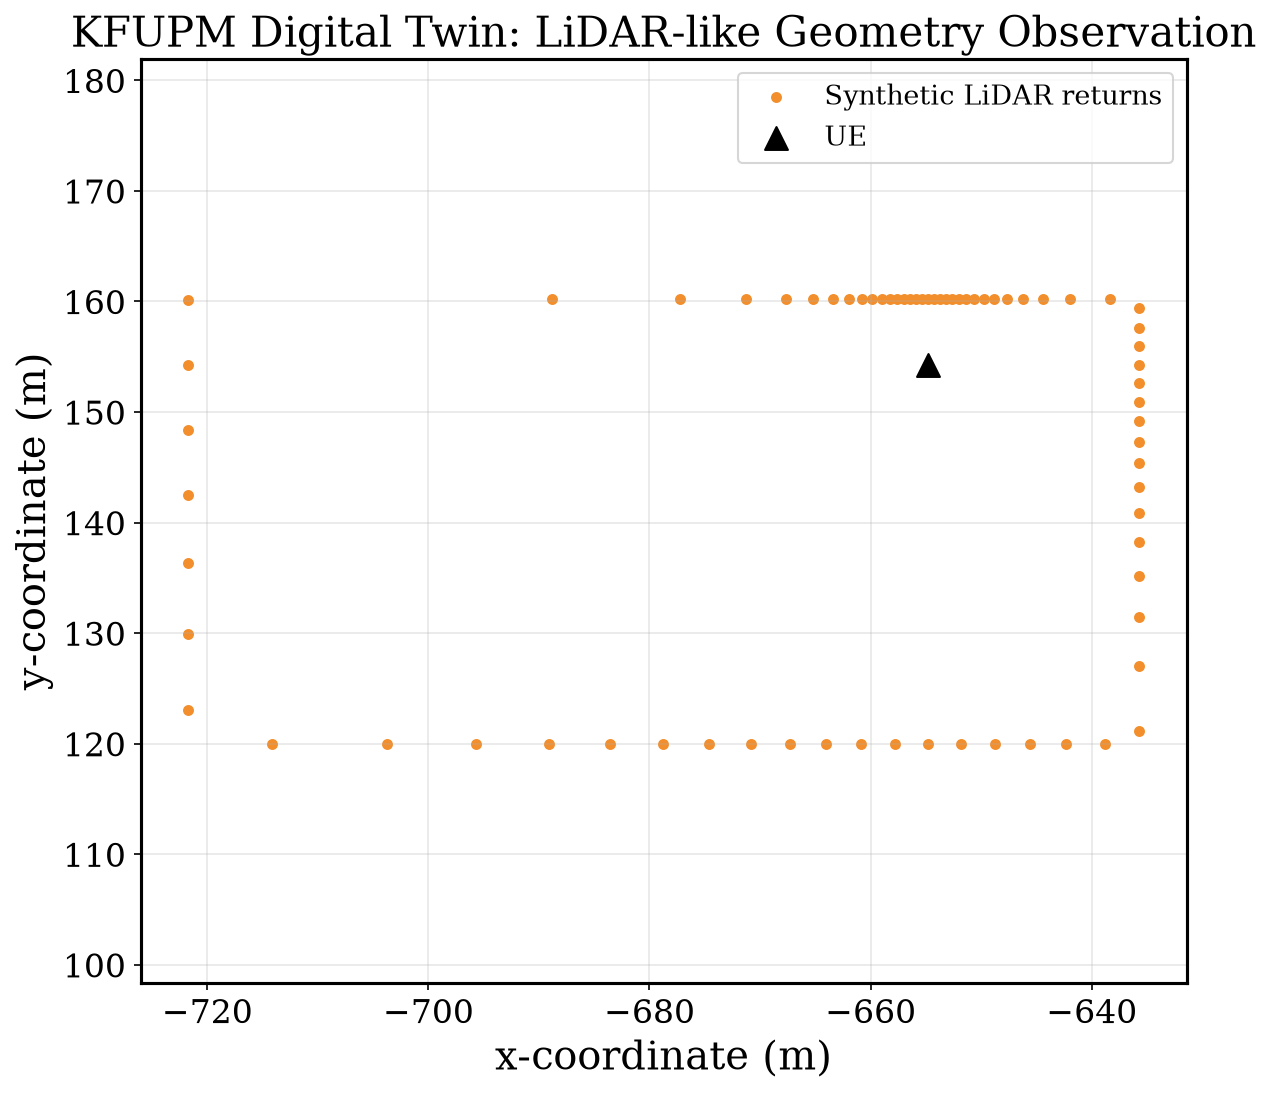

In [46]:
record = digital_twin_records[len(digital_twin_records)//2]

angles = record["lidar_angles"]
ranges = record["lidar_ranges"]
position = record["position"]

lidar_x = position[0] + ranges * np.cos(angles)
lidar_y = position[1] + ranges * np.sin(angles)

plt.figure(figsize=(9, 8))

plt.scatter(
    lidar_x,
    lidar_y,
    s=18,
    color="#F28E2B",
    label="Synthetic LiDAR returns",
)

plt.scatter(
    position[0],
    position[1],
    s=120,
    color="black",
    marker="^",
    label="UE",
)

plt.xlim(
    position[0] - 150,
    position[0] + 150,
)

plt.ylim(
    position[1] - 150,
    position[1] + 150,
)

plt.xlabel("x-coordinate (m)")
plt.ylabel("y-coordinate (m)")
plt.title("KFUPM Digital Twin: LiDAR-like Geometry Observation")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [47]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

image_dir = Path(
    "/home/afanali/wcnc_project/data/rgb_frames"
)

image_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Select one route observation
record_index = len(digital_twin_records) // 2
record = digital_twin_records[record_index]

ue_position = np.asarray(record["position"], dtype=float)

# Use the UE mobility direction to determine the camera viewing direction
route_index = record["route_index"]

if route_index < len(ue_route) - 1:
    next_position = np.asarray(
        ue_route[min(route_index + 1, len(ue_route) - 1)]
    )
else:
    next_position = np.asarray(
        ue_route[max(route_index - 1, 0)]
    )

direction = next_position - ue_position
direction = direction / (np.linalg.norm(direction) + 1e-9)

# Camera slightly above the UE
camera_position = ue_position + np.array([0.0, 0.0, 1.6])

# Look ahead along the route
look_at = camera_position + 80.0 * direction
look_at[2] = camera_position[2]

camera = rt.Camera(
    position=camera_position.tolist(),
    look_at=look_at.tolist(),
)

rgb_path = image_dir / f"rgb_frame_{record_index:04d}.png"

scene.render_to_file(
    camera=camera,
    filename=str(rgb_path),
    resolution=[960, 720],
    num_samples=64,
)

record["rgb_path"] = str(rgb_path)

print("RGB image saved to:")
print(rgb_path)

RGB image saved to:
/home/afanali/wcnc_project/data/rgb_frames/rgb_frame_0010.png


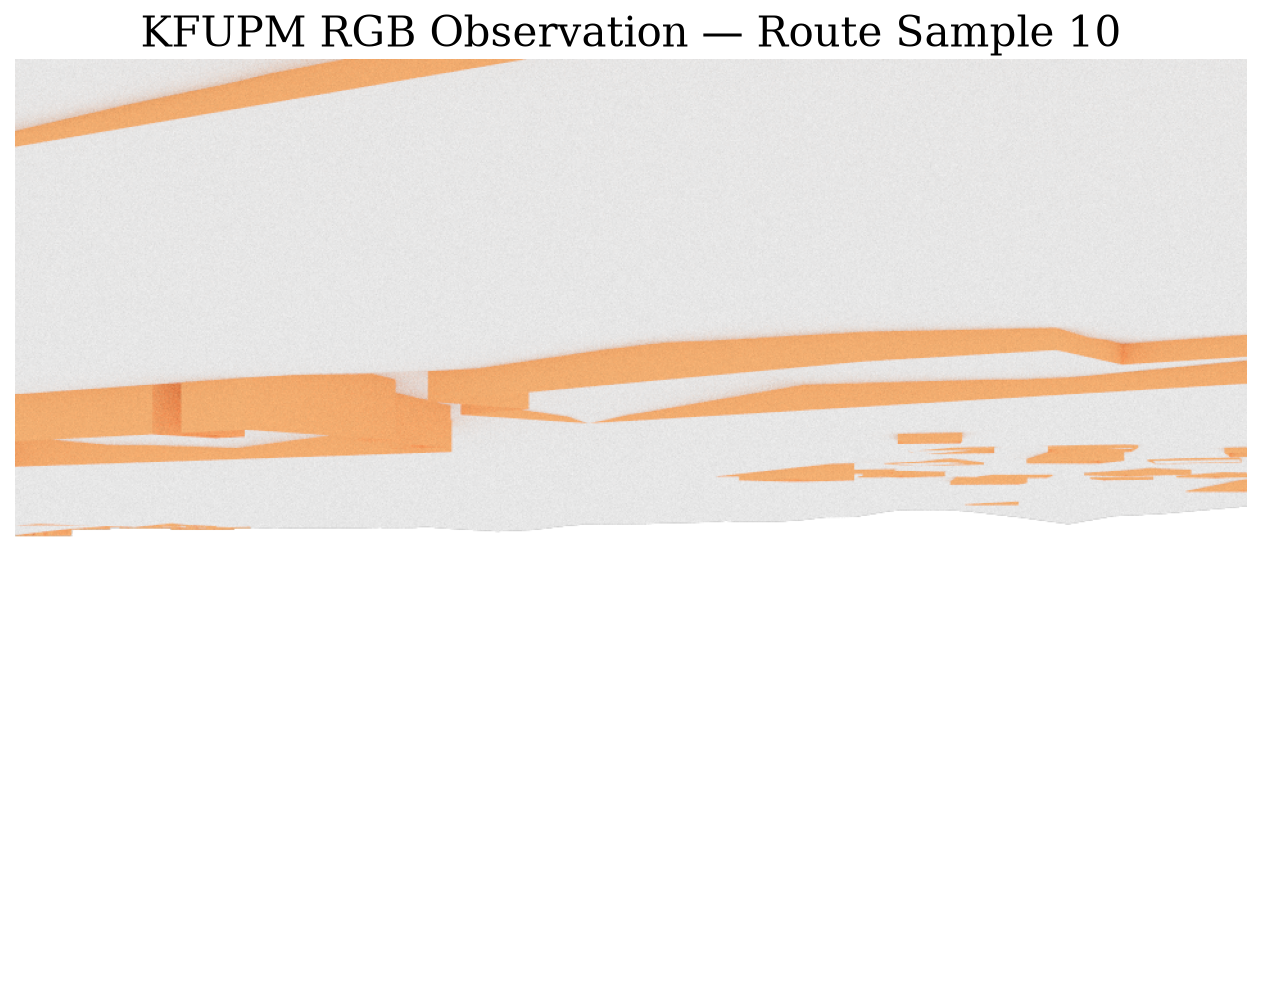

In [48]:
rgb_image = plt.imread(
    digital_twin_records[record_index]["rgb_path"]
)

plt.figure(figsize=(12, 8))
plt.imshow(rgb_image)
plt.axis("off")
plt.title(
    f"KFUPM RGB Observation — Route Sample {record_index}"
)
plt.show()

In [49]:
digital_twin_records[record_index]["rgb_path"]

'/home/afanali/wcnc_project/data/rgb_frames/rgb_frame_0010.png'

In [50]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

depth_dir = Path(
    "/home/afanali/wcnc_project/data/depth_frames"
)

depth_dir.mkdir(
    parents=True,
    exist_ok=True,
)

for record_index, record in enumerate(digital_twin_records):

    ranges = np.asarray(
        record["lidar_ranges"],
        dtype=np.float32,
    )

    # Replace maximum-range values with the sensor maximum
    max_range = 250.0
    ranges = np.clip(ranges, 0.0, max_range)

    # Convert the 1-D angular scan into a compact depth image
    depth_image = ranges.reshape(1, -1)

    depth_path = depth_dir / (
        f"depth_frame_{record_index:04d}.png"
    )

    plt.imsave(
        depth_path,
        depth_image,
        cmap="viridis",
        vmin=0.0,
        vmax=max_range,
    )

    record["depth_path"] = str(depth_path)
    record["depth_image"] = depth_image

print("Depth images generated:", len(digital_twin_records))
print("Example depth image:")
print(digital_twin_records[0]["depth_path"])

Depth images generated: 20
Example depth image:
/home/afanali/wcnc_project/data/depth_frames/depth_frame_0000.png


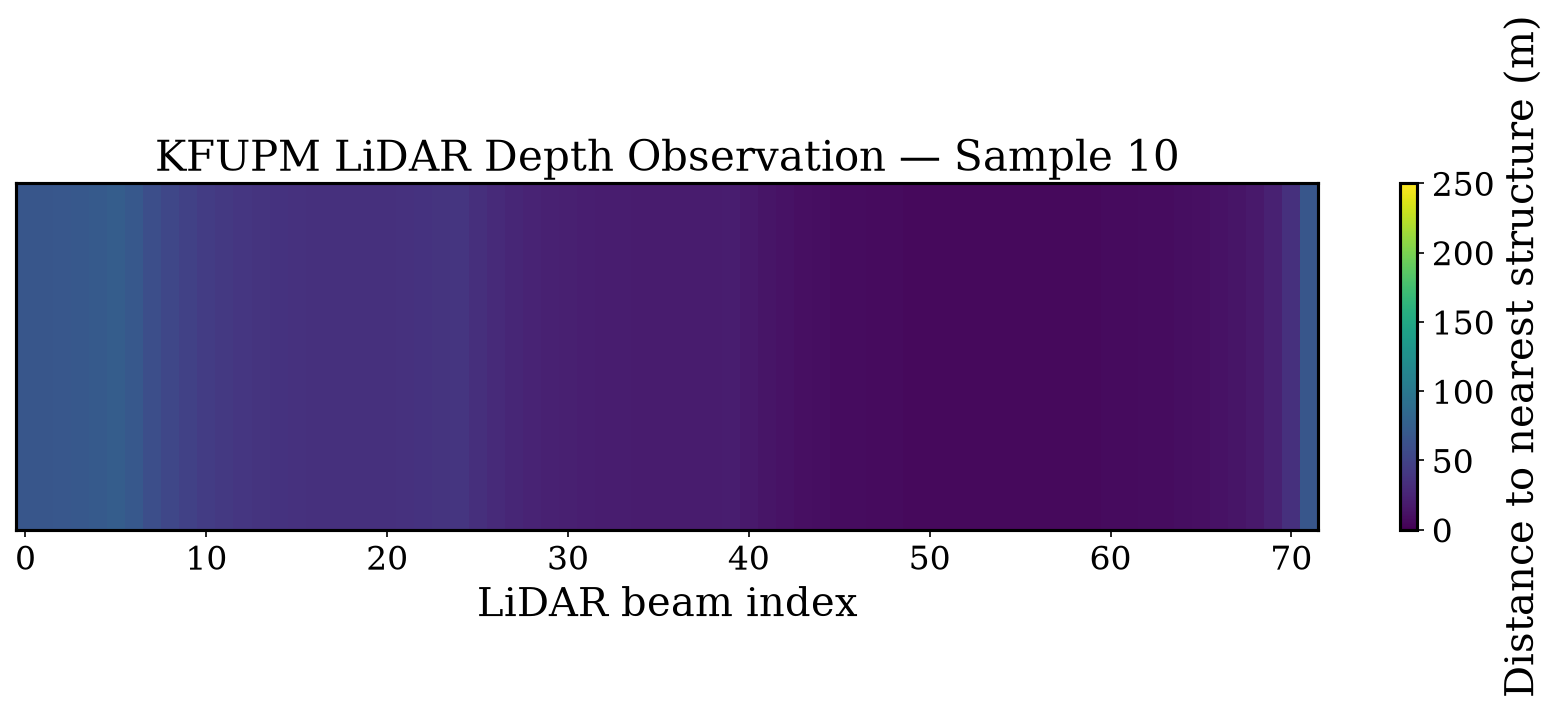

In [51]:
record_index = len(digital_twin_records) // 2
depth_image = digital_twin_records[record_index]["depth_image"]

plt.figure(figsize=(14, 3))

plt.imshow(
    depth_image,
    cmap="viridis",
    aspect="auto",
    vmin=0.0,
    vmax=250.0,
)

plt.colorbar(
    label="Distance to nearest structure (m)"
)

plt.xlabel("LiDAR beam index")
plt.yticks([])
plt.title(
    f"KFUPM LiDAR Depth Observation — Sample {record_index}"
)

plt.show()

In [52]:
import numpy as np

# RF features: average channel power for the three gNBs
rf_features = np.stack([
    np.asarray(record["channel_power_db"]).reshape(-1)
    for record in digital_twin_records
])

# Mobility features
mobility_features = np.stack([
    np.concatenate([
        np.asarray(record["position"]).reshape(-1),
        np.asarray(record["velocity"]).reshape(-1),
        np.asarray(record["acceleration"]).reshape(-1),
        np.asarray([record["heading"]]),
    ])
    for record in digital_twin_records
])

# LiDAR/depth features
lidar_features = np.stack([
    np.asarray(record["lidar_ranges"]).reshape(-1)
    for record in digital_twin_records
])

# Combined numerical multimodal state
multimodal_features = np.concatenate(
    [
        rf_features,
        mobility_features,
        lidar_features,
    ],
    axis=1,
)

print("RF feature shape:", rf_features.shape)
print("Mobility feature shape:", mobility_features.shape)
print("LiDAR feature shape:", lidar_features.shape)
print("Combined multimodal feature shape:", multimodal_features.shape)

RF feature shape: (20, 3)
Mobility feature shape: (20, 10)
LiDAR feature shape: (20, 72)
Combined multimodal feature shape: (20, 85)


In [54]:
multimodal_dataset = []

for index, record in enumerate(digital_twin_records):

    multimodal_dataset.append({
        "time_index": index,
        "route_index": record["route_index"],
        "position": record["position"],
        "velocity": record["velocity"],
        "acceleration": record["acceleration"],
        "heading": record["heading"],
        "rf_power_db": rf_features[index],
        "lidar_ranges": lidar_features[index],
        "rgb_path": record.get("rgb_path", None),
        "depth_path": record.get("depth_path", None),
        "best_gnb": record["best_gnb"],
        "valid_path_counts": record["valid_path_counts"],
    })

print("Multimodal observations:", len(multimodal_dataset))
print("Available fields:")
print(multimodal_dataset[0].keys())

Multimodal observations: 20
Available fields:
dict_keys(['time_index', 'route_index', 'position', 'velocity', 'acceleration', 'heading', 'rf_power_db', 'lidar_ranges', 'rgb_path', 'depth_path', 'best_gnb', 'valid_path_counts'])


In [55]:
class DigitalTwinObservationAgent:
    """
    Collects synchronized RF, mobility, and LiDAR observations
    from the KFUPM Digital Twin.
    """

    def __init__(self, dataset):
        self.dataset = dataset

    def observe_environment(self, time_index):
        observation = self.dataset[time_index]

        return {
            "time_index": observation["time_index"],
            "route_index": observation["route_index"],
            "position": observation["position"],
            "velocity": observation["velocity"],
            "acceleration": observation["acceleration"],
            "heading": observation["heading"],
            "rf_power_db": observation["rf_power_db"],
            "lidar_ranges": observation["lidar_ranges"],
            "valid_path_counts": observation["valid_path_counts"],
            "best_gnb": observation["best_gnb"],
        }


observation_agent = DigitalTwinObservationAgent(
    multimodal_dataset
)

current_state = observation_agent.observe_environment(0)

print("Observation agent initialized.")
print("Current UE position:", current_state["position"])
print("RF powers:", current_state["rf_power_db"])
print("Valid paths:", current_state["valid_path_counts"])
print("Current best gNB:", current_state["best_gnb"] + 1)

Observation agent initialized.
Current UE position: [-513.92763472  207.96310632   45.        ]
RF powers: [-110.34321 -104.339   -300.     ]
Valid paths: [11 10  0]
Current best gNB: 2


In [56]:
class LinkQualityAgent:
    """
    Evaluates candidate gNBs using RF strength and path availability.
    """

    def __init__(
        self,
        min_rf_power_db=-300.0,
        path_bonus_db=1.0,
    ):
        self.min_rf_power_db = min_rf_power_db
        self.path_bonus_db = path_bonus_db

    def evaluate(self, observation):

        rf_power = np.asarray(
            observation["rf_power_db"],
            dtype=float,
        )

        valid_paths = np.asarray(
            observation["valid_path_counts"],
            dtype=float,
        )

        path_confidence = (
            valid_paths > 0
        ).astype(float) * self.path_bonus_db

        candidate_scores = rf_power + path_confidence

        # Exclude gNBs with no valid paths
        candidate_scores[valid_paths <= 0] = -300.0

        return {
            "candidate_scores_db": candidate_scores,
            "recommended_gnb": int(np.argmax(candidate_scores)),
            "path_confidence": path_confidence,
        }


link_quality_agent = LinkQualityAgent()

quality_result = link_quality_agent.evaluate(
    current_state
)

print(
    "Candidate scores:",
    np.round(
        quality_result["candidate_scores_db"],
        2,
    ),
)

print(
    "Recommended gNB:",
    quality_result["recommended_gnb"] + 1,
)

Candidate scores: [-109.34 -103.34 -300.  ]
Recommended gNB: 2


In [57]:
class MultimodalForecastingAgent:
    """
    Predicts future RF quality using recent RF, mobility,
    and LiDAR observations.
    """

    def __init__(self, dataset, history_length=3):
        self.dataset = dataset
        self.history_length = history_length

    def _get_history(self, time_index):
        start = max(
            0,
            time_index - self.history_length + 1,
        )

        return self.dataset[start:time_index + 1]

    def forecast_rf(self, time_index, horizon=3):
        history = self._get_history(time_index)

        rf_history = np.stack([
            np.asarray(item["rf_power_db"])
            for item in history
        ])

        # One observation: persistence
        if len(rf_history) < 2:
            predicted_rf = np.repeat(
                rf_history[-1][None, :],
                horizon,
                axis=0,
            )

        else:
            # Estimate recent RF trend
            slope = rf_history[-1] - rf_history[-2]

            predicted_rf = np.array([
                rf_history[-1] + (step + 1) * slope
                for step in range(horizon)
            ])

        return predicted_rf

    def forecast(self, time_index, horizon=3):
        predicted_rf = self.forecast_rf(
            time_index,
            horizon,
        )

        return {
            "predicted_rf_power_db": predicted_rf,
            "horizon": horizon,
        }


forecasting_agent = MultimodalForecastingAgent(
    multimodal_dataset,
    history_length=3,
)

forecast_result = forecasting_agent.forecast(
    time_index=len(multimodal_dataset) // 2,
    horizon=3,
)

print("Forecasted RF shape:")
print(
    forecast_result["predicted_rf_power_db"].shape
)

print("\nPredicted RF power:")
print(
    np.round(
        forecast_result["predicted_rf_power_db"],
        2,
    )
)

Forecasted RF shape:
(3, 3)

Predicted RF power:
[[-300.   -490.84   36.15]
 [-300.   -681.69  204.22]
 [-300.   -872.53  372.29]]


In [58]:
class PredictiveHandoverAgent:
    """
    Selects a serving or target gNB from predicted future RF quality.
    """

    def __init__(
        self,
        hysteresis_db=3.0,
        min_valid_paths=1,
    ):
        self.hysteresis_db = hysteresis_db
        self.min_valid_paths = min_valid_paths

    def decide(
        self,
        observation,
        forecast,
        serving_gnb=None,
    ):
        current_rf = np.asarray(
            observation["rf_power_db"],
            dtype=float,
        )

        valid_paths = np.asarray(
            observation["valid_path_counts"],
            dtype=int,
        )

        predicted_rf = np.asarray(
            forecast["predicted_rf_power_db"],
            dtype=float,
        )

        # Average predicted quality over the forecast horizon
        predicted_score = predicted_rf.mean(axis=0)

        # Exclude cells without valid propagation paths
        predicted_score[
            valid_paths < self.min_valid_paths
        ] = -300.0

        best_future_gnb = int(
            np.argmax(predicted_score)
        )

        if serving_gnb is None:
            serving_gnb = int(np.argmax(current_rf))

        current_serving_quality = current_rf[serving_gnb]
        target_quality = predicted_score[best_future_gnb]

        gain = target_quality - current_serving_quality

        if (
            best_future_gnb != serving_gnb
            and gain >= self.hysteresis_db
        ):
            action = "handover"
            selected_gnb = best_future_gnb
        else:
            action = "stay"
            selected_gnb = serving_gnb

        return {
            "action": action,
            "serving_gnb": serving_gnb,
            "selected_gnb": selected_gnb,
            "predicted_scores_db": predicted_score,
            "predicted_gain_db": gain,
        }


decision_agent = PredictiveHandoverAgent(
    hysteresis_db=3.0,
)

decision_result = decision_agent.decide(
    observation=current_state,
    forecast=forecast_result,
    serving_gnb=0,
)

print("Decision:", decision_result["action"])
print(
    "Current serving gNB:",
    decision_result["serving_gnb"] + 1,
)
print(
    "Selected gNB:",
    decision_result["selected_gnb"] + 1,
)
print(
    "Predicted gain:",
    round(
        float(decision_result["predicted_gain_db"]),
        2,
    ),
    "dB",
)

Decision: stay
Current serving gNB: 1
Selected gNB: 1
Predicted gain: -189.66 dB


In [59]:
class HandoverSafetyAgent:
    """
    Validates a proposed handover using RF quality,
    path availability, and minimum residence time.
    """

    def __init__(
        self,
        minimum_power_db=-140.0,
        minimum_valid_paths=1,
        minimum_residence_steps=3,
    ):
        self.minimum_power_db = minimum_power_db
        self.minimum_valid_paths = minimum_valid_paths
        self.minimum_residence_steps = minimum_residence_steps

    def validate(
        self,
        observation,
        decision,
        steps_since_last_handover=999,
    ):
        target = decision["selected_gnb"]
        action = decision["action"]

        rf_power = float(
            observation["rf_power_db"][target]
        )

        valid_paths = int(
            observation["valid_path_counts"][target]
        )

        reasons = []
        safe = True

        if rf_power < self.minimum_power_db:
            safe = False
            reasons.append("target RF quality is too weak")

        if valid_paths < self.minimum_valid_paths:
            safe = False
            reasons.append("target has no valid propagation paths")

        if (
            action == "handover"
            and steps_since_last_handover
            < self.minimum_residence_steps
        ):
            safe = False
            reasons.append("minimum residence time not satisfied")

        if safe:
            reasons.append("handover satisfies safety constraints")

        return {
            "safe": safe,
            "action": action if safe else "stay",
            "target_gnb": target,
            "reasons": reasons,
        }


safety_agent = HandoverSafetyAgent(
    minimum_power_db=-140.0,
    minimum_valid_paths=1,
    minimum_residence_steps=3,
)

safety_result = safety_agent.validate(
    observation=current_state,
    decision=decision_result,
    steps_since_last_handover=999,
)

print("Safety-approved:", safety_result["safe"])
print("Final action:", safety_result["action"])
print("Target gNB:", safety_result["target_gnb"] + 1)

for reason in safety_result["reasons"]:
    print("-", reason)

Safety-approved: True
Final action: stay
Target gNB: 1
- handover satisfies safety constraints


In [60]:
class AgenticHandoverController:
    """
    Closed-loop Agentic AI controller that:
    1. Observes the Digital Twin
    2. Evaluates current link quality
    3. Forecasts future RF quality
    4. Proposes a handover
    5. Validates it through the Safety Agent
    6. Updates the serving gNB
    """

    def __init__(
        self,
        observation_agent,
        link_quality_agent,
        forecasting_agent,
        decision_agent,
        safety_agent,
    ):
        self.observation_agent = observation_agent
        self.link_quality_agent = link_quality_agent
        self.forecasting_agent = forecasting_agent
        self.decision_agent = decision_agent
        self.safety_agent = safety_agent

        self.serving_gnb = None
        self.steps_since_last_handover = 999
        self.history = []

    def step(self, time_index, horizon=3):

        observation = (
            self.observation_agent
            .observe_environment(time_index)
        )

        # Initialize serving gNB
        if self.serving_gnb is None:
            self.serving_gnb = int(
                np.argmax(
                    observation["rf_power_db"]
                )
            )

        quality = (
            self.link_quality_agent
            .evaluate(observation)
        )

        forecast = (
            self.forecasting_agent
            .forecast(
                time_index=time_index,
                horizon=horizon,
            )
        )

        decision = (
            self.decision_agent
            .decide(
                observation=observation,
                forecast=forecast,
                serving_gnb=self.serving_gnb,
            )
        )

        safety = (
            self.safety_agent
            .validate(
                observation=observation,
                decision=decision,
                steps_since_last_handover=(
                    self.steps_since_last_handover
                ),
            )
        )

        previous_serving = self.serving_gnb

        if (
            safety["safe"]
            and safety["action"] == "handover"
        ):
            self.serving_gnb = safety["target_gnb"]
            self.steps_since_last_handover = 0
        else:
            self.steps_since_last_handover += 1

        result = {
            "time_index": time_index,
            "position": observation["position"],
            "serving_before": previous_serving,
            "serving_after": self.serving_gnb,
            "recommended_gnb": quality["recommended_gnb"],
            "decision_action": decision["action"],
            "safety_action": safety["action"],
            "safety_approved": safety["safe"],
            "predicted_scores_db": (
                decision["predicted_scores_db"]
            ),
            "reasons": safety["reasons"],
        }

        self.history.append(result)

        return result

In [61]:
agentic_controller = AgenticHandoverController(
    observation_agent=observation_agent,
    link_quality_agent=link_quality_agent,
    forecasting_agent=forecasting_agent,
    decision_agent=decision_agent,
    safety_agent=safety_agent,
)

agentic_results = []

for time_index in range(
    len(multimodal_dataset)
):
    result = agentic_controller.step(
        time_index=time_index,
        horizon=3,
    )

    agentic_results.append(result)

    print(
        f"Step {time_index:02d} | "
        f"Serving: gNB{result['serving_after'] + 1} | "
        f"Decision: {result['decision_action']:9s} | "
        f"Safety: {result['safety_action']:9s}"
    )

print(
    "\nAgentic AI simulation completed:",
    len(agentic_results),
    "steps",
)

Step 00 | Serving: gNB2 | Decision: stay      | Safety: stay     
Step 01 | Serving: gNB2 | Decision: stay      | Safety: stay     
Step 02 | Serving: gNB2 | Decision: stay      | Safety: stay     
Step 03 | Serving: gNB3 | Decision: handover  | Safety: handover 
Step 04 | Serving: gNB3 | Decision: handover  | Safety: stay     
Step 05 | Serving: gNB3 | Decision: handover  | Safety: stay     
Step 06 | Serving: gNB3 | Decision: handover  | Safety: stay     
Step 07 | Serving: gNB1 | Decision: handover  | Safety: handover 
Step 08 | Serving: gNB1 | Decision: stay      | Safety: stay     
Step 09 | Serving: gNB1 | Decision: handover  | Safety: stay     
Step 10 | Serving: gNB1 | Decision: handover  | Safety: stay     
Step 11 | Serving: gNB1 | Decision: stay      | Safety: stay     
Step 12 | Serving: gNB1 | Decision: stay      | Safety: stay     
Step 13 | Serving: gNB1 | Decision: stay      | Safety: stay     
Step 14 | Serving: gNB3 | Decision: handover  | Safety: handover 
Step 15 | 

In [62]:
handover_count = sum(
    result["serving_before"]
    != result["serving_after"]
    for result in agentic_results
)

print("Total approved handovers:", handover_count)

Total approved handovers: 4


In [63]:
rf_sequence = np.stack([
    np.asarray(record["rf_power_db"])
    for record in multimodal_dataset
])

valid_sequence = np.stack([
    np.asarray(record["valid_path_counts"])
    for record in multimodal_dataset
])

num_steps, num_gnbs = rf_sequence.shape

best_current_gnb = np.argmax(
    rf_sequence,
    axis=1,
)

print("RF sequence shape:", rf_sequence.shape)
print("Number of route samples:", num_steps)

RF sequence shape: (20, 3)
Number of route samples: 20


In [64]:
def run_persistence_baseline(rf_sequence):
    """
    Keeps the initial serving gNB throughout the route.
    """
    initial_gnb = int(
        np.argmax(rf_sequence[0])
    )

    return np.full(
        len(rf_sequence),
        initial_gnb,
        dtype=int,
    )


def run_event_a3_baseline(
    rf_sequence,
    hysteresis_db=2.0,
    ttt_steps=3,
):
    """
    Simplified Event-A3 controller.
    """

    serving = np.zeros(
        len(rf_sequence),
        dtype=int,
    )

    serving[0] = int(
        np.argmax(rf_sequence[0])
    )

    candidate = serving[0]
    trigger_count = 0

    for t in range(1, len(rf_sequence)):

        current = serving[t - 1]
        best = int(
            np.argmax(rf_sequence[t])
        )

        if (
            best != current
            and rf_sequence[t, best]
            >= rf_sequence[t, current]
            + hysteresis_db
        ):
            if candidate == best:
                trigger_count += 1
            else:
                candidate = best
                trigger_count = 1

            if trigger_count >= ttt_steps:
                serving[t] = best
                candidate = best
                trigger_count = 0
            else:
                serving[t] = current

        else:
            candidate = current
            trigger_count = 0
            serving[t] = current

    return serving


def run_agentic_serving(agentic_results):
    return np.array([
        result["serving_after"]
        for result in agentic_results
    ])

In [65]:
serving_persistence = run_persistence_baseline(
    rf_sequence
)

serving_a3 = run_event_a3_baseline(
    rf_sequence,
    hysteresis_db=2.0,
    ttt_steps=3,
)

serving_agentic = run_agentic_serving(
    agentic_results
)

serving_oracle = best_current_gnb.copy()

print("Benchmark serving sequences generated.")

Benchmark serving sequences generated.


In [66]:
def count_handovers(serving_sequence):
    return int(
        np.sum(
            serving_sequence[1:]
            != serving_sequence[:-1]
        )
    )


def calculate_metrics(
    name,
    serving_sequence,
    rf_sequence,
    weak_threshold=-140.0,
):
    time_indices = np.arange(
        len(serving_sequence)
    )

    serving_rf = rf_sequence[
        time_indices,
        serving_sequence,
    ]

    best_rf = np.max(
        rf_sequence,
        axis=1,
    )

    return {
        "method": name,
        "mean_rf_db": float(
            np.mean(serving_rf)
        ),
        "p5_rf_db": float(
            np.percentile(serving_rf, 5)
        ),
        "handovers": count_handovers(
            serving_sequence
        ),
        "off_best_percent": float(
            np.mean(
                serving_sequence
                != best_current_gnb
            ) * 100
        ),
        "weak_coverage_percent": float(
            np.mean(
                serving_rf < weak_threshold
            ) * 100
        ),
        "mean_best_gap_db": float(
            np.mean(best_rf - serving_rf)
        ),
    }


benchmark_results = [
    calculate_metrics(
        "Persistence",
        serving_persistence,
        rf_sequence,
    ),
    calculate_metrics(
        "Event-A3",
        serving_a3,
        rf_sequence,
    ),
    calculate_metrics(
        "Simple Agentic AI",
        serving_agentic,
        rf_sequence,
    ),
    calculate_metrics(
        "Best-current oracle",
        serving_oracle,
        rf_sequence,
    ),
]

for result in benchmark_results:
    print(
        f"{result['method']:20s} | "
        f"Mean RF: {result['mean_rf_db']:8.2f} dB | "
        f"P5 RF: {result['p5_rf_db']:8.2f} dB | "
        f"HO: {result['handovers']:2d} | "
        f"Off-best: {result['off_best_percent']:6.1f}% | "
        f"Weak: {result['weak_coverage_percent']:6.1f}%"
    )

Persistence          | Mean RF:  -161.95 dB | P5 RF:  -300.00 dB | HO:  0 | Off-best:   55.0% | Weak:   25.0%
Event-A3             | Mean RF:  -123.01 dB | P5 RF:  -135.22 dB | HO:  1 | Off-best:   40.0% | Weak:    5.0%
Simple Agentic AI    | Mean RF:  -171.20 dB | P5 RF:  -300.00 dB | HO:  4 | Off-best:   55.0% | Weak:   30.0%
Best-current oracle  | Mean RF:  -112.53 dB | P5 RF:  -125.34 dB | HO:  7 | Off-best:    0.0% | Weak:    0.0%


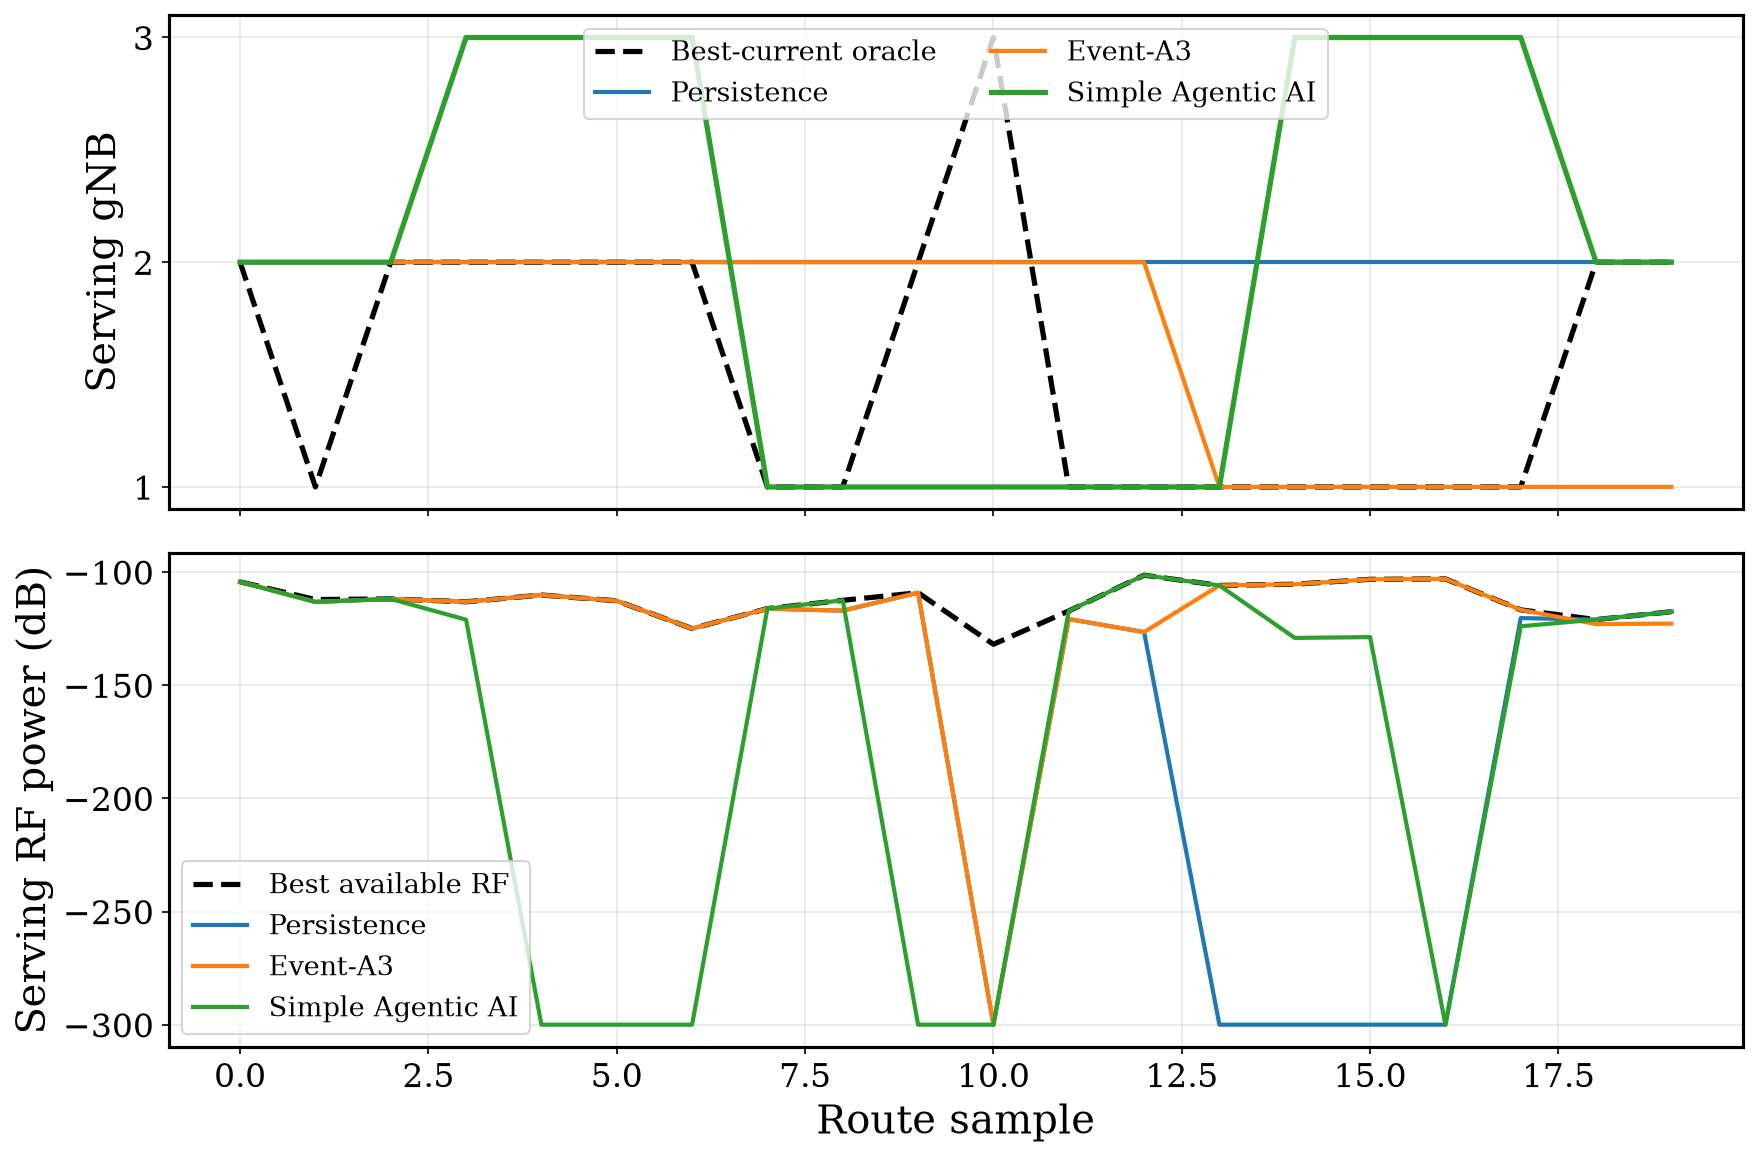

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

benchmark_df = pd.DataFrame(
    benchmark_results
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 8),
    sharex=True,
)

time_axis = np.arange(
    len(rf_sequence)
)

axes[0].plot(
    time_axis,
    best_current_gnb + 1,
    "k--",
    linewidth=2.5,
    label="Best-current oracle",
)

axes[0].plot(
    time_axis,
    serving_persistence + 1,
    linewidth=2,
    label="Persistence",
)

axes[0].plot(
    time_axis,
    serving_a3 + 1,
    linewidth=2,
    label="Event-A3",
)

axes[0].plot(
    time_axis,
    serving_agentic + 1,
    linewidth=2.5,
    label="Simple Agentic AI",
)

axes[0].set_ylabel("Serving gNB")
axes[0].set_yticks([1, 2, 3])
axes[0].grid(alpha=0.3)
axes[0].legend(
    ncol=2,
    loc="upper center",
)

axes[1].plot(
    time_axis,
    np.max(rf_sequence, axis=1),
    "k--",
    linewidth=2.5,
    label="Best available RF",
)

for name, sequence in [
    ("Persistence", serving_persistence),
    ("Event-A3", serving_a3),
    ("Simple Agentic AI", serving_agentic),
]:
    axes[1].plot(
        time_axis,
        rf_sequence[
            time_axis,
            sequence,
        ],
        linewidth=2,
        label=name,
    )

axes[1].set_xlabel("Route sample")
axes[1].set_ylabel("Serving RF power (dB)")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

Benchmark data saved:
/home/afanali/wcnc_project/results/benchmark_route_data.csv
/home/afanali/wcnc_project/results/benchmark_route_data.npz


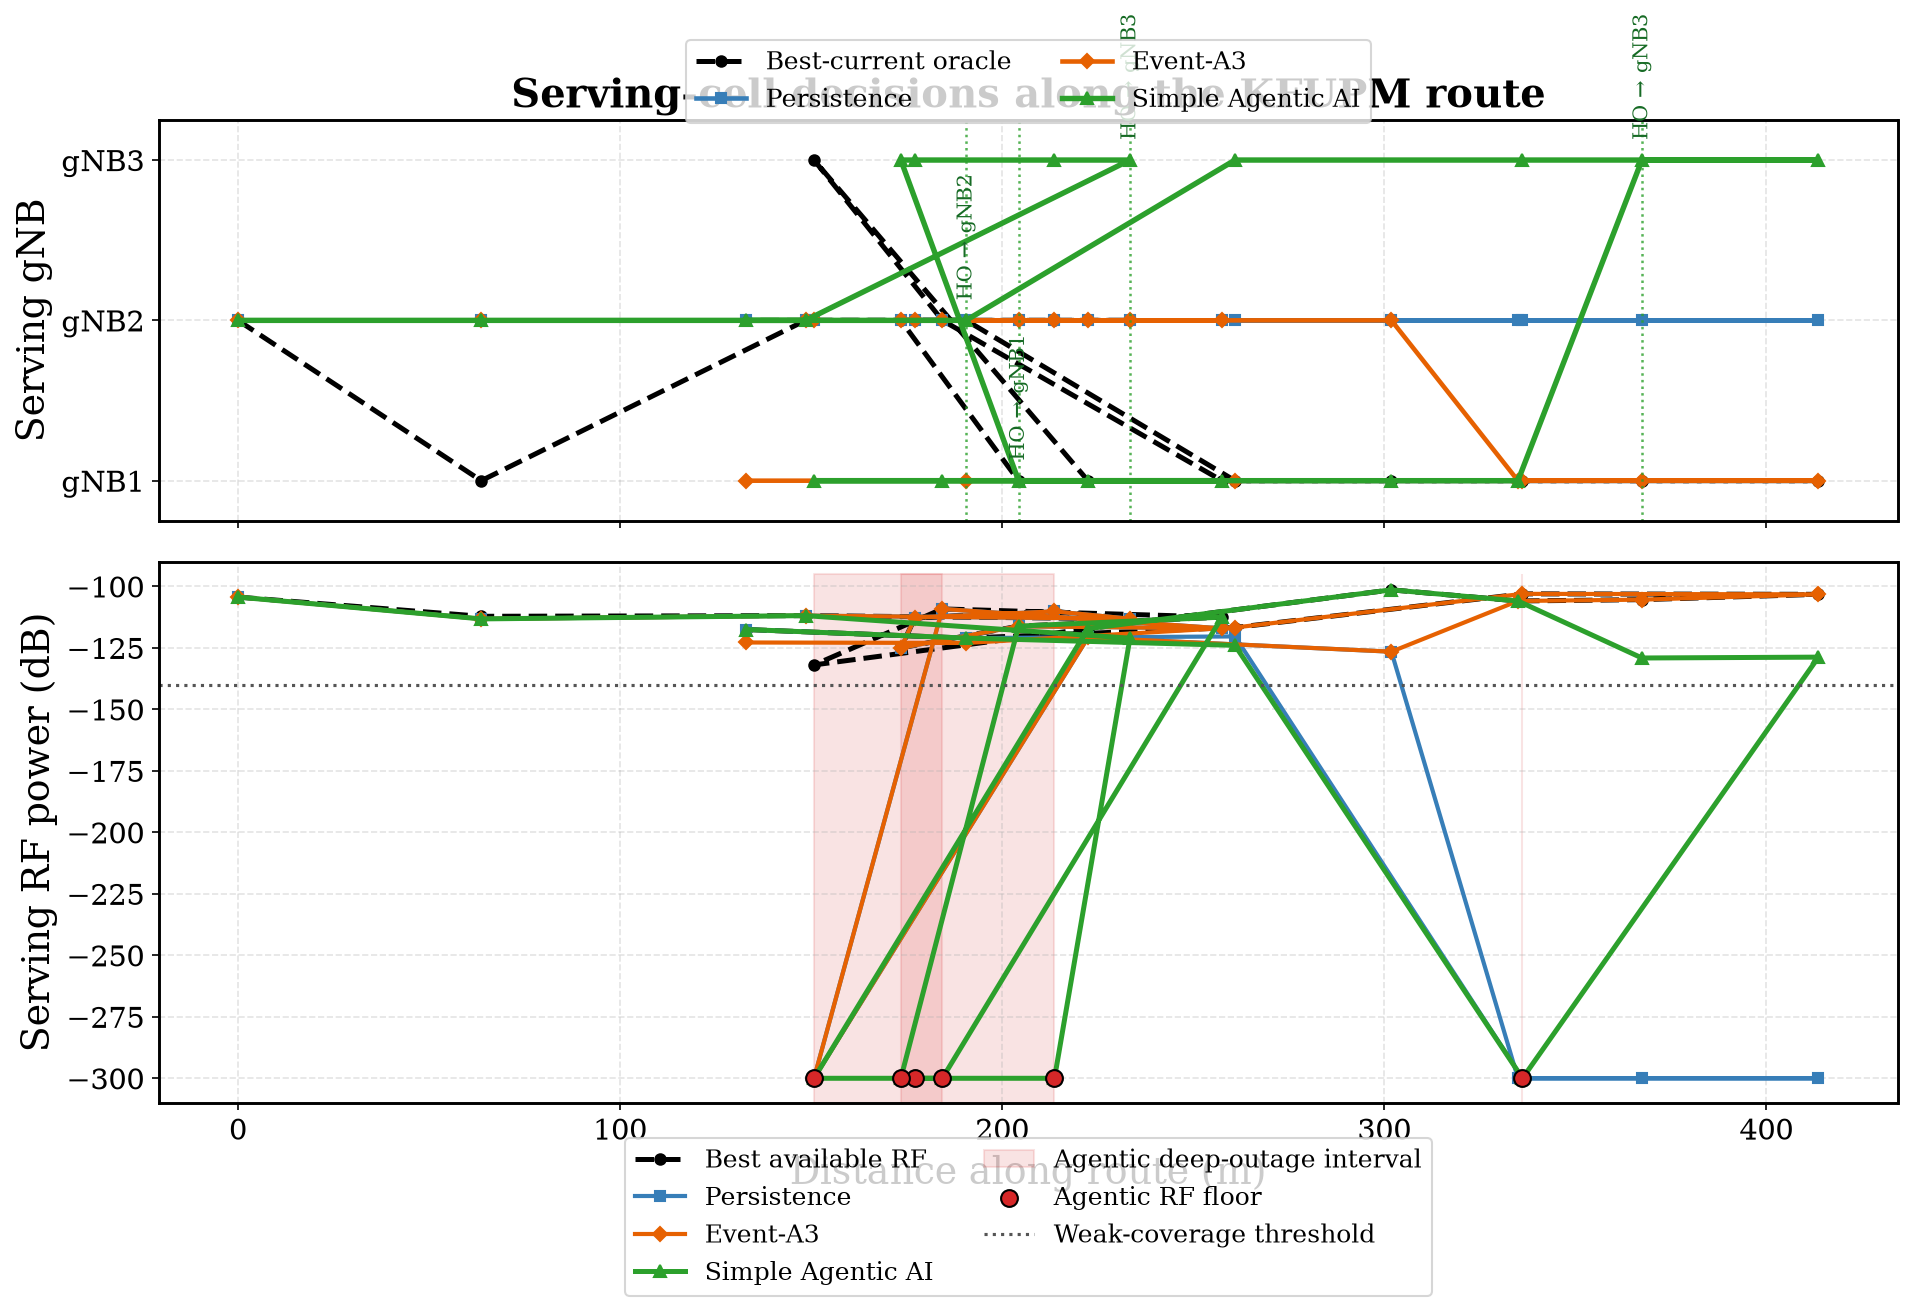


Figures saved:
/home/afanali/wcnc_project/figures/benchmark_serving_decisions_IEEE.pdf
/home/afanali/wcnc_project/figures/benchmark_serving_decisions_IEEE.png


In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

num_steps = len(rf_sequence)

# Route distance for each sampled observation
sampled_distance = np.array([
    np.linalg.norm(
        ue_route[
            sample_indices[i]
        ] - ue_route[0]
    )
    for i in range(num_steps)
])

best_rf = np.max(rf_sequence, axis=1)

serving_rf_persistence = rf_sequence[
    np.arange(num_steps),
    serving_persistence,
]

serving_rf_a3 = rf_sequence[
    np.arange(num_steps),
    serving_a3,
]

serving_rf_agentic = rf_sequence[
    np.arange(num_steps),
    serving_agentic,
]

serving_rf_oracle = rf_sequence[
    np.arange(num_steps),
    serving_oracle,
]

# ------------------------------------------------------------
# Save all benchmark data for future figures
# ------------------------------------------------------------

benchmark_table = pd.DataFrame({
    "sample_index": np.arange(num_steps),
    "route_index": sample_indices,
    "distance_m": sampled_distance,
    "best_gnb": best_current_gnb + 1,
    "best_rf_db": best_rf,
    "persistence_gnb": serving_persistence + 1,
    "persistence_rf_db": serving_rf_persistence,
    "event_a3_gnb": serving_a3 + 1,
    "event_a3_rf_db": serving_rf_a3,
    "agentic_gnb": serving_agentic + 1,
    "agentic_rf_db": serving_rf_agentic,
    "oracle_gnb": serving_oracle + 1,
    "oracle_rf_db": serving_rf_oracle,
})

figure_dir = Path(
    "/home/afanali/wcnc_project/figures"
)

results_dir = Path(
    "/home/afanali/wcnc_project/results"
)

figure_dir.mkdir(
    parents=True,
    exist_ok=True,
)

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

csv_path = results_dir / "benchmark_route_data.csv"
npz_path = results_dir / "benchmark_route_data.npz"

benchmark_table.to_csv(
    csv_path,
    index=False,
)

np.savez(
    npz_path,
    sample_index=np.arange(num_steps),
    route_index=sample_indices,
    distance_m=sampled_distance,
    rf_sequence=rf_sequence,
    best_current_gnb=best_current_gnb,
    serving_persistence=serving_persistence,
    serving_a3=serving_a3,
    serving_agentic=serving_agentic,
    serving_oracle=serving_oracle,
)

print("Benchmark data saved:")
print(csv_path)
print(npz_path)

# ------------------------------------------------------------
# Create enhanced IEEE-style plot
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 18,
    "axes.titlesize": 19,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "axes.linewidth": 1.4,
})

fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1.35]},
)

# ------------------------------------------------------------
# Upper panel: serving cell
# ------------------------------------------------------------

axes[0].plot(
    sampled_distance,
    best_current_gnb + 1,
    "k--",
    linewidth=2.4,
    marker="o",
    markersize=5,
    label="Best-current oracle",
)

axes[0].plot(
    sampled_distance,
    serving_persistence + 1,
    color="#377EB8",
    linewidth=2.2,
    marker="s",
    markersize=5,
    label="Persistence",
)

axes[0].plot(
    sampled_distance,
    serving_a3 + 1,
    color="#E66101",
    linewidth=2.2,
    marker="D",
    markersize=5,
    label="Event-A3",
)

axes[0].plot(
    sampled_distance,
    serving_agentic + 1,
    color="#2CA02C",
    linewidth=2.6,
    marker="^",
    markersize=6,
    label="Simple Agentic AI",
)

axes[0].set_ylabel("Serving gNB")
axes[0].set_yticks([1, 2, 3])
axes[0].set_yticklabels(["gNB1", "gNB2", "gNB3"])
axes[0].set_ylim(0.75, 3.25)
axes[0].grid(
    True,
    linestyle="--",
    alpha=0.35,
)

axes[0].set_title(
    "Serving-cell decisions along the KFUPM route",
    fontweight="bold",
)

axes[0].legend(
    ncol=2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.23),
    frameon=True,
)

# Mark agentic handover points
agentic_handover_indices = np.where(
    serving_agentic[1:]
    != serving_agentic[:-1]
)[0] + 1

for idx in agentic_handover_indices:
    axes[0].axvline(
        sampled_distance[idx],
        color="#2CA02C",
        linestyle=":",
        linewidth=1.2,
        alpha=0.8,
    )

    axes[0].annotate(
        f"HO → gNB{serving_agentic[idx] + 1}",
        xy=(
            sampled_distance[idx],
            serving_agentic[idx] + 1,
        ),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color="#176B25",
        rotation=90,
    )

# ------------------------------------------------------------
# Lower panel: serving RF power
# ------------------------------------------------------------

axes[1].plot(
    sampled_distance,
    best_rf,
    "k--",
    linewidth=2.4,
    marker="o",
    markersize=5,
    label="Best available RF",
)

axes[1].plot(
    sampled_distance,
    serving_rf_persistence,
    color="#377EB8",
    linewidth=2.0,
    marker="s",
    markersize=5,
    label="Persistence",
)

axes[1].plot(
    sampled_distance,
    serving_rf_a3,
    color="#E66101",
    linewidth=2.0,
    marker="D",
    markersize=5,
    label="Event-A3",
)

axes[1].plot(
    sampled_distance,
    serving_rf_agentic,
    color="#2CA02C",
    linewidth=2.4,
    marker="^",
    markersize=6,
    label="Simple Agentic AI",
)

# Highlight invalid/deep-outage RF values
invalid_agentic = serving_rf_agentic <= -250.0

if np.any(invalid_agentic):
    axes[1].fill_between(
        sampled_distance,
        -310,
        -95,
        where=invalid_agentic,
        color="#D62728",
        alpha=0.13,
        label="Agentic deep-outage interval",
    )

    axes[1].scatter(
        sampled_distance[invalid_agentic],
        serving_rf_agentic[invalid_agentic],
        color="#D62728",
        edgecolor="black",
        s=65,
        zorder=8,
        label="Agentic RF floor",
    )

axes[1].axhline(
    -140,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label="Weak-coverage threshold",
)

axes[1].set_xlabel("Distance along route (m)")
axes[1].set_ylabel("Serving RF power (dB)")
axes[1].set_ylim(-310, -90)
axes[1].grid(
    True,
    linestyle="--",
    alpha=0.35,
)

axes[1].legend(
    ncol=2,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.38),
    frameon=True,
)

plt.tight_layout()

# Save publication and preview versions
pdf_path = figure_dir / "benchmark_serving_decisions_IEEE.pdf"
png_path = figure_dir / "benchmark_serving_decisions_IEEE.png"

fig.savefig(
    pdf_path,
    bbox_inches="tight",
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("\nFigures saved:")
print(pdf_path)
print(png_path)